# Анализ и прогнозирование цен подержанных автомобилей

**Команда № 180**

| Участник | Группа |
|---|---|
| Павчун Дмитрий | 8 |
| Алимова Яна | 11 |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

from scipy import stats
from statsmodels.stats.weightstats import ztest
from statsmodels.stats.proportion import proportions_ztest

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)

## 1. Описание данных

In [2]:
df = pd.read_excel('Автомобили.xlsx')
print('Размер датасета:', df.shape)
df.head()

Размер датасета: (700, 13)


,Производитель,Модель,"Возраст автомобиля, лет","Пробег, миль",Состояние,Тип кузова,Тип топлива,Электромобиль,Коробка передач,Привод,Количество цилиндров,Цвет,"Цена, USD"
0,Ford,super duty f-250 srw,5,118000,Отличное,Грузовик,Дизель,Нет,Автоматическая,Полный,8.0,Черный,43900
1,Chevrolet,silverado 1500,4,133329,Хорошее,Грузовик,Бензин,Нет,Автоматическая,Полный,8.0,Серебристый,26990
2,Ford,thunderbird,18,33970,Отличное,Кабриолет,Бензин,Нет,Автоматическая,Задний,8.0,Красный,18990
3,Ford,f150 platinum 4x4,9,175489,Как новый,Пикап,Бензин,Нет,Автоматическая,Полный,NaN,Черный,14777
4,Tesla,model 3,3,18900,Отличное,Седан,Электричество,Да,Другое,Задний,0.0,Белый,42200


- **Тема датасета:** объявления о продаже подержанных автомобилей на американском рынке: марка и модель, возраст, пробег, техническое состояние, характеристики кузова и двигателя, цвет и цена.
- **Одно наблюдение:** один автомобиль, выставленный на продажу.
- **Источник:** Used Cars Dataset, платформа Kaggle. Исходный массив содержал 426 880 строк. Предобработка до нас: удалены дубликаты, строки с пропущенными ключевыми характеристиками и наблюдения с неправдоподобными ценами, годами выпуска или пробегом. Из очищенных данных отобраны 700 автомобилей разных марок, типов кузова, ценовых категорий и видов топлива, включая электромобили и гибриды. Названия признаков и категорий переведены на русский язык, марки, модели и числовые значения оставлены на английском.
- **Размер:** 700 наблюдений и 13 признаков.
- **Целевой признак:** `Цена, USD` — цена автомобиля в долларах. Признак количественный, поэтому для его прогноза используется линейная регрессия.

## 2. Описание признаков

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Производитель            700 non-null    str    
 1   Модель                   700 non-null    str    
 2   Возраст автомобиля, лет  700 non-null    int64  
 3   Пробег, миль             700 non-null    int64  
 4   Состояние                700 non-null    str    
 5   Тип кузова               700 non-null    str    
 6   Тип топлива              700 non-null    str    
 7   Электромобиль            700 non-null    str    
 8   Коробка передач          700 non-null    str    
 9   Привод                   660 non-null    str    
 10  Количество цилиндров     673 non-null    float64
 11  Цвет                     682 non-null    str    
 12  Цена, USD                700 non-null    int64  
dtypes: float64(1), int64(3), str(9)
memory usage: 71.2 KB


| № | Признак | Описание | Формат (pandas) | Тип данных |
|---|---|---|---|---|
| 1 | Производитель | Марка автомобиля (Ford, Toyota, Tesla и т.д.) | object | Категориальный номинальный |
| 2 | Модель | Модель автомобиля | object | Категориальный номинальный |
| 3 | Возраст автомобиля, лет | Сколько лет прошло с года выпуска | int64 | Количественный дискретный |
| 4 | Пробег, миль | Пробег по одометру | int64 | Количественный непрерывный |
| 5 | Состояние | Техническое состояние: Аварийное < Удовлетворительное < Хорошее < Отличное < Как новый < Новый | object | Категориальный порядковый |
| 6 | Тип кузова | Седан, внедорожник, пикап и т.д. | object | Категориальный номинальный |
| 7 | Тип топлива | Бензин, дизель, гибрид, электричество, другое | object | Категориальный номинальный |
| 8 | Электромобиль | Является ли автомобиль электромобилем (Да/Нет) | object | Категориальный бинарный |
| 9 | Коробка передач | Автоматическая, механическая, другое | object | Категориальный номинальный |
| 10 | Привод | Передний, задний, полный | object | Категориальный номинальный |
| 11 | Количество цилиндров | Число цилиндров двигателя (0 у электромобилей) | float64 | Количественный дискретный |
| 12 | Цвет | Цвет кузова | object | Категориальный номинальный |
| 13 | Цена, USD | Цена продажи в долларах (**целевой признак**) | int64 | Количественный непрерывный |

**Комментарии к классификации:**

- `Количество цилиндров` считается в целых единицах, но имеет формат `float64`: в признаке есть пропуски (`NaN`), а `NaN` в pandas — это значение типа float, целочисленный `int64` его хранить не может. Поэтому весь столбец приводится к `float64`. По смыслу признак количественный дискретный.
- `Состояние` — единственный порядковый признак: его категории выстраиваются в осмысленную последовательность от худшего к лучшему. У остальных категориальных признаков порядка нет (нельзя сказать, что «белый» больше «синего»).
- `Электромобиль` — бинарный: ровно два значения, Да и Нет.
- `Пробег` и `Цена` отнесены к непрерывным: это измеряемые величины, которые могут принимать любое значение на интервале, а целые числа в данных — результат округления.

## 3. Пропуски и дубликаты

In [4]:
missing = pd.DataFrame({
    'Количество пропусков': df.isna().sum(),
    'Доля пропусков, %': (df.isna().mean() * 100).round(2)
})
missing[missing['Количество пропусков'] > 0]

,Количество пропусков,"Доля пропусков, %"
Привод,40,5.71
Количество цилиндров,27,3.86
Цвет,18,2.57


In [5]:
print('Полных дубликатов строк:', df.duplicated().sum())

Полных дубликатов строк: 35


In [6]:
df_clean = df.drop_duplicates().copy()

df_clean['Привод'] = df_clean['Привод'].fillna(df_clean['Привод'].mode()[0])
df_clean['Цвет'] = df_clean['Цвет'].fillna(df_clean['Цвет'].mode()[0])
df_clean['Количество цилиндров'] = df_clean['Количество цилиндров'].fillna(
    df_clean['Количество цилиндров'].median())

df_clean['Количество цилиндров'] = df_clean['Количество цилиндров'].astype('int64')

print('Мода «Привод»:', df_clean['Привод'].mode()[0])
print('Мода «Цвет»:', df_clean['Цвет'].mode()[0])
print('Медиана «Количество цилиндров»:', df.drop_duplicates()['Количество цилиндров'].median())
print('Пропусков после заполнения:', df_clean.isna().sum().sum())
print('Размер df_clean:', df_clean.shape)

Мода «Привод»: Полный
Мода «Цвет»: Белый
Медиана «Количество цилиндров»: 6.0
Пропусков после заполнения: 0
Размер df_clean: (665, 13)


**Выводы:**

- Пропуски есть в трёх признаках: `Привод` — 40 (5.71%), `Количество цилиндров` — 27 (3.86%), `Цвет` — 18 (2.57%). Доля везде меньше 6%, поэтому строки не удаляем, а заполняем пропуски.
- Найдено 35 полных дубликатов строк. Это повторно размещённые объявления, они удалены. Дубликаты удаляются до заполнения пропусков, чтобы повторы не искажали моду и медиану.
- **Привод** и **Цвет** — категориальные номинальные признаки, заполняем **модой** (Полный и Белый). Для текстовых меток можно посчитать только частоту, поэтому мода — единственная применимая мера центральной тенденции: среднее и медиана для слов не существуют.
- **Количество цилиндров** — количественный дискретный признак, заполняем **медианой** (6). Среднее (5.59) дробное, а дробного числа цилиндров не бывает, к тому же оно чувствительно к крайним значениям (0 у электромобилей, 10 у мощных двигателей). Медиана устойчива к ним и даёт реальное значение. Мода (8) лишь самое частое значение и не отражает центр распределения, где много 4- и 6-цилиндровых моторов.
- После заполнения пропусков `Количество цилиндров` приведён к `int64`, так как причина формата `float64` (наличие `NaN`) устранена.
- Итог: **df_clean — 665 строк, 13 признаков, пропусков нет.**

## 4. Выбросы

### 4.1. Ящики с усами

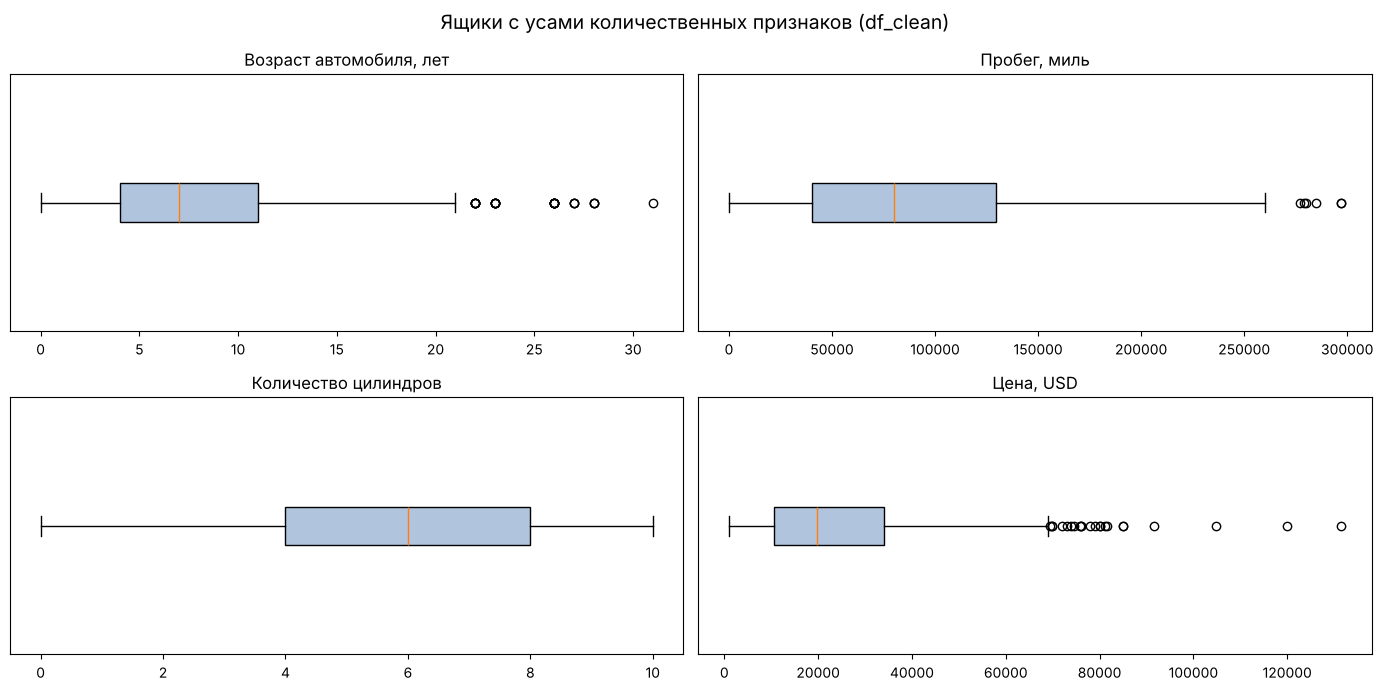

Возраст автомобиля, лет   правый ус:       21.5 | точек справа:  26 | точек слева: 0
Пробег, миль              правый ус:  263,781.0 | точек справа:   6 | точек слева: 0
Количество цилиндров      правый ус:       14.0 | точек справа:   0 | точек слева: 0
Цена, USD                 правый ус:   69,237.5 | точек справа:  22 | точек слева: 0


In [7]:
num_cols = ['Возраст автомобиля, лет', 'Пробег, миль', 'Количество цилиндров', 'Цена, USD']

fig, axes = plt.subplots(2, 2, figsize=(14, 7))
for ax, col in zip(axes.flatten(), num_cols):
    ax.boxplot(df_clean[col], vert=False, patch_artist=True,
               boxprops=dict(facecolor='lightsteelblue'))
    ax.set_title(col)
    ax.set_yticks([])
plt.suptitle('Ящики с усами количественных признаков (df_clean)', fontsize=14)
plt.tight_layout()
plt.show()

# сколько точек лежит за усами (граница уса = Q3 + 1.5·IQR и Q1 − 1.5·IQR)
for col in num_cols:
    q1, q3 = df_clean[col].quantile(0.25), df_clean[col].quantile(0.75)
    iqr = q3 - q1
    print(f'{col:25} правый ус: {q3 + 1.5 * iqr:>10,.1f} | точек справа: '
          f'{(df_clean[col] > q3 + 1.5 * iqr).sum():>3} | точек слева: '
          f'{(df_clean[col] < q1 - 1.5 * iqr).sum()}')

**Выводы:**

- `Цена, USD` — 22 точки за правым усом (дороже 69 238 USD), максимум 131 500 при медиане около 20 тыс. Распределение сильно скошено вправо.
- `Пробег, миль` — 6 выбросов справа, машины с пробегом выше 263 781 мили.
- `Возраст автомобиля, лет` — 26 точек справа: машины старше 21.5 года. Три четверти автомобилей не старше 11 лет.
- `Количество цилиндров` — выбросов нет: все значения от 0 (электромобили) до 10 лежат внутри усов.
- Слева выбросов нет ни у одного признака, все хвосты направлены вправо.
- Параметр `vert=False` разворачивает ящики горизонтально: значения признака идут по оси X, так длинные хвосты удобнее читать.

### 4.2. Метод N стандартных отклонений

In [8]:
price = df_clean['Цена, USD']
N = 3
mean_p, std_p = price.mean(), price.std()
low_std, high_std = mean_p - N * std_p, mean_p + N * std_p

df_no_std = df_clean[price.between(low_std, high_std)].copy()

print(f'Среднее: {mean_p:,.0f}, стандартное отклонение: {std_p:,.0f}')
print(f'Границы: {low_std:,.0f} ... {high_std:,.0f}')
print('Удалено строк:', len(df_clean) - len(df_no_std))
print('Размер df_no_std:', df_no_std.shape)

Среднее: 24,543, стандартное отклонение: 18,785
Границы: -31,811 ... 80,898
Удалено строк: 8
Размер df_no_std: (657, 13)


**Выводы:**

- Согласно разъяснению ассистента, выбросы отслеживаются прежде всего по предикторам, но отдельно проверить целевую переменную также полезно. Поэтому методом N стандартных отклонений чистим целевую переменную `Цена, USD`, а предиктор `Пробег, миль` — методом 1.5 × IQR в п. 4.3.
- Выбрано **N = 3**. При N = 3 за пределы интервала попадает около 0.3% наблюдений нормального распределения, то есть удаляются только явно аномальные значения. При N = 2 удалилось бы 30 строк (4.5% выборки), в том числе обычные дорогие, но реальные автомобили, а мы потеряли бы информацию для регрессии.
- Границы: **−31 811 ... 80 898 USD**. Удалено **8** автомобилей дороже 80 898 USD (от 81 250 до 131 500), это премиальные машины, нетипичные для выборки.
- Итог: **df_no_std — 657 строк.**

### 4.3. Метод 1.5 × IQR

In [9]:
mileage = df_no_std['Пробег, миль']
Q1, Q3 = mileage.quantile(0.25), mileage.quantile(0.75)
IQR = Q3 - Q1
low_iqr, high_iqr = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

df_final = df_no_std[mileage.between(low_iqr, high_iqr)].copy()

print(f'Q1 = {Q1:,.0f}, Q3 = {Q3:,.0f}, IQR = {IQR:,.0f}')
print(f'Границы: {low_iqr:,.0f} ... {high_iqr:,.0f}')
print('Удалено строк:', len(df_no_std) - len(df_final))
print('Размер df_final:', df_final.shape)
print('Цепочка размеров:', len(df), '→', len(df_clean), '→', len(df_no_std), '→', len(df_final))

Q1 = 42,616, Q3 = 129,960, IQR = 87,344
Границы: -88,400 ... 260,976
Удалено строк: 6
Размер df_final: (651, 13)
Цепочка размеров: 700 → 665 → 657 → 651


**Выводы:**

- Чистим предиктор `Пробег, миль`, данные берём уже из `df_no_std`.
- Q1 = 42 616, Q3 = 129 960, IQR = 87 344 мили. Границы: **−88 400 ... 260 976** миль.
- Удалено **6** автомобилей с пробегом выше 260 976 миль (до 297 тыс.). Такой пробег сильно выделяется на фоне остальных и может быть ошибкой ввода.
- Итог: **df_final — 651 строка.**

**Почему левая граница в обоих методах отрицательная:**

- Оба признака скошены вправо: основная масса значений сосредоточена у нуля, а длинный правый хвост сильно увеличивает разброс.
- В методе N·STD стандартное отклонение цены (18 785) большое относительно среднего (24 543), поэтому среднее − 3·std уходит ниже нуля. В методе IQR межквартильный размах (87 344) больше Q1 (42 616), поэтому Q1 − 1.5·IQR тоже отрицательная.
- Формулы симметричны относительно центра и не учитывают, что цена и пробег не бывают отрицательными. Значит, левая граница здесь ничего не отсекает и фактически работает только правая: выбросы в этих данных есть только сверху.

Дальше во всех разделах работаем с **df_final**.

## 5. Визуализация

### 5.1. Распределение количественных признаков

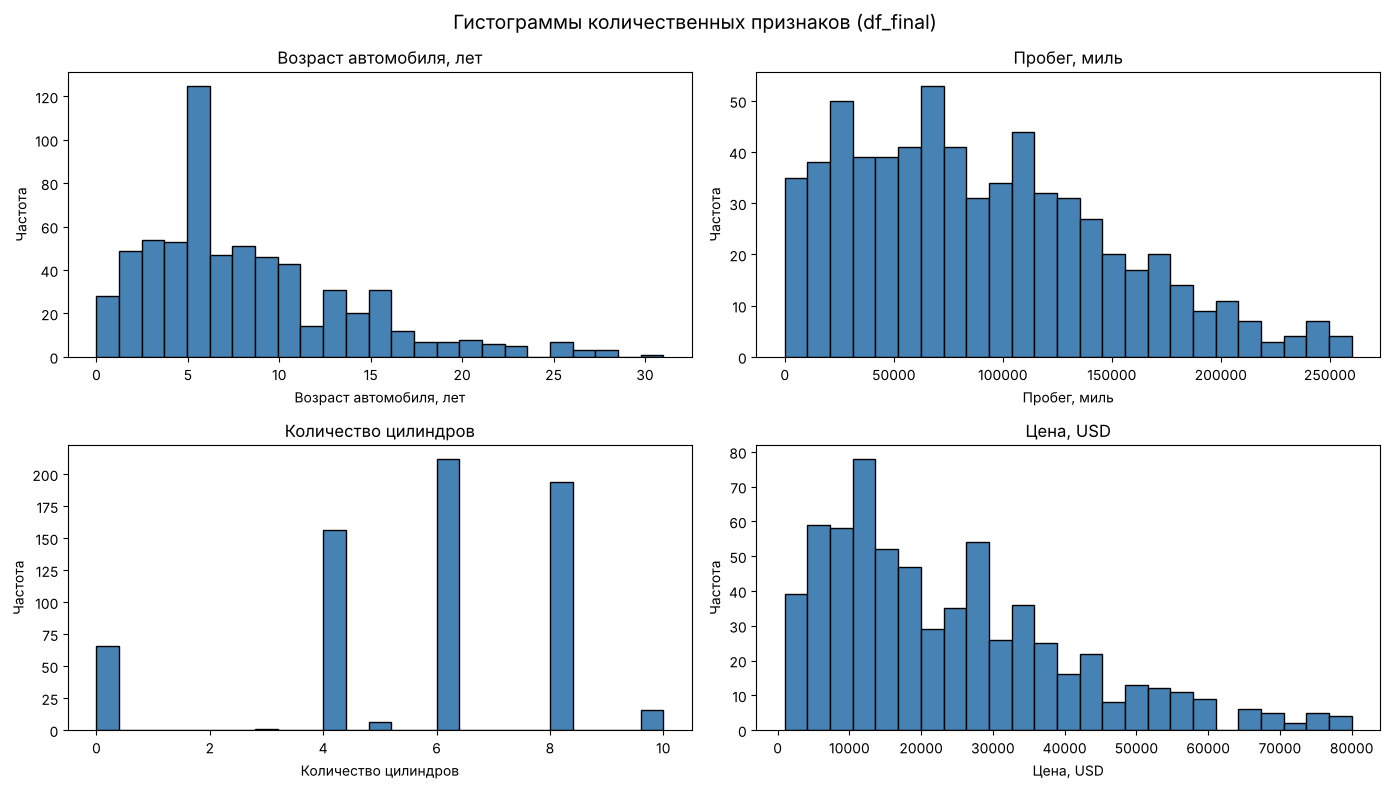

Коэффициенты асимметрии:
Возраст автомобиля, лет    1.21
Пробег, миль               0.60
Количество цилиндров      -0.84
Цена, USD                  1.02
dtype: float64


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, col in zip(axes.flatten(), num_cols):
    df_final[col].plot(kind='hist', bins=25, ax=ax, edgecolor='black', color='steelblue')
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel('Частота')
plt.suptitle('Гистограммы количественных признаков (df_final)', fontsize=14)
plt.tight_layout()
plt.show()

print('Коэффициенты асимметрии:')
print(df_final[num_cols].skew().round(2))

**Выводы по распределению количественных признаков:**

- **Цена, USD** — распределение скошено вправо, коэффициент асимметрии **1.02**. Пик приходится на интервал 5–15 тыс. USD, затем частота плавно снижается, а справа тянется хвост дорогих автомобилей вплоть до 80 тыс. Среднее (23 767) заметно выше медианы (19 500) — характерный признак правосторонней скошенности: длинный правый хвост тянет среднее вверх.
- **Пробег, миль** — умеренная правосторонняя скошенность, **0.60**. Распределение ближе к симметричному, чем у цены: чаще всего встречаются машины с пробегом 40–130 тыс. миль, но есть заметная группа почти новых автомобилей с пробегом близким к нулю.
- **Возраст автомобиля, лет** — самая сильная скошенность среди количественных признаков, **1.21**. Больше половины машин моложе 8 лет, после 15 лет частота резко падает, отдельные наблюдения доходят до 31 года.
- **Количество цилиндров** — распределение дискретное, с левосторонней скошенностью (**−0.84**). Хорошо видны три пика: 4 цилиндра (156 машин), 6 (212) и 8 (194). Отдельно стоит группа со значением 0 — это 66 электромобилей, у которых двигателя внутреннего сгорания нет. Промежуточные значения (3, 5, 10) встречаются единично.
- Общий вывод: все денежные и «пробежные» признаки скошены вправо, что типично для рыночных данных — дешёвых и массовых объектов всегда больше, чем дорогих и редких.

### 5.2. Распределение категориальных признаков

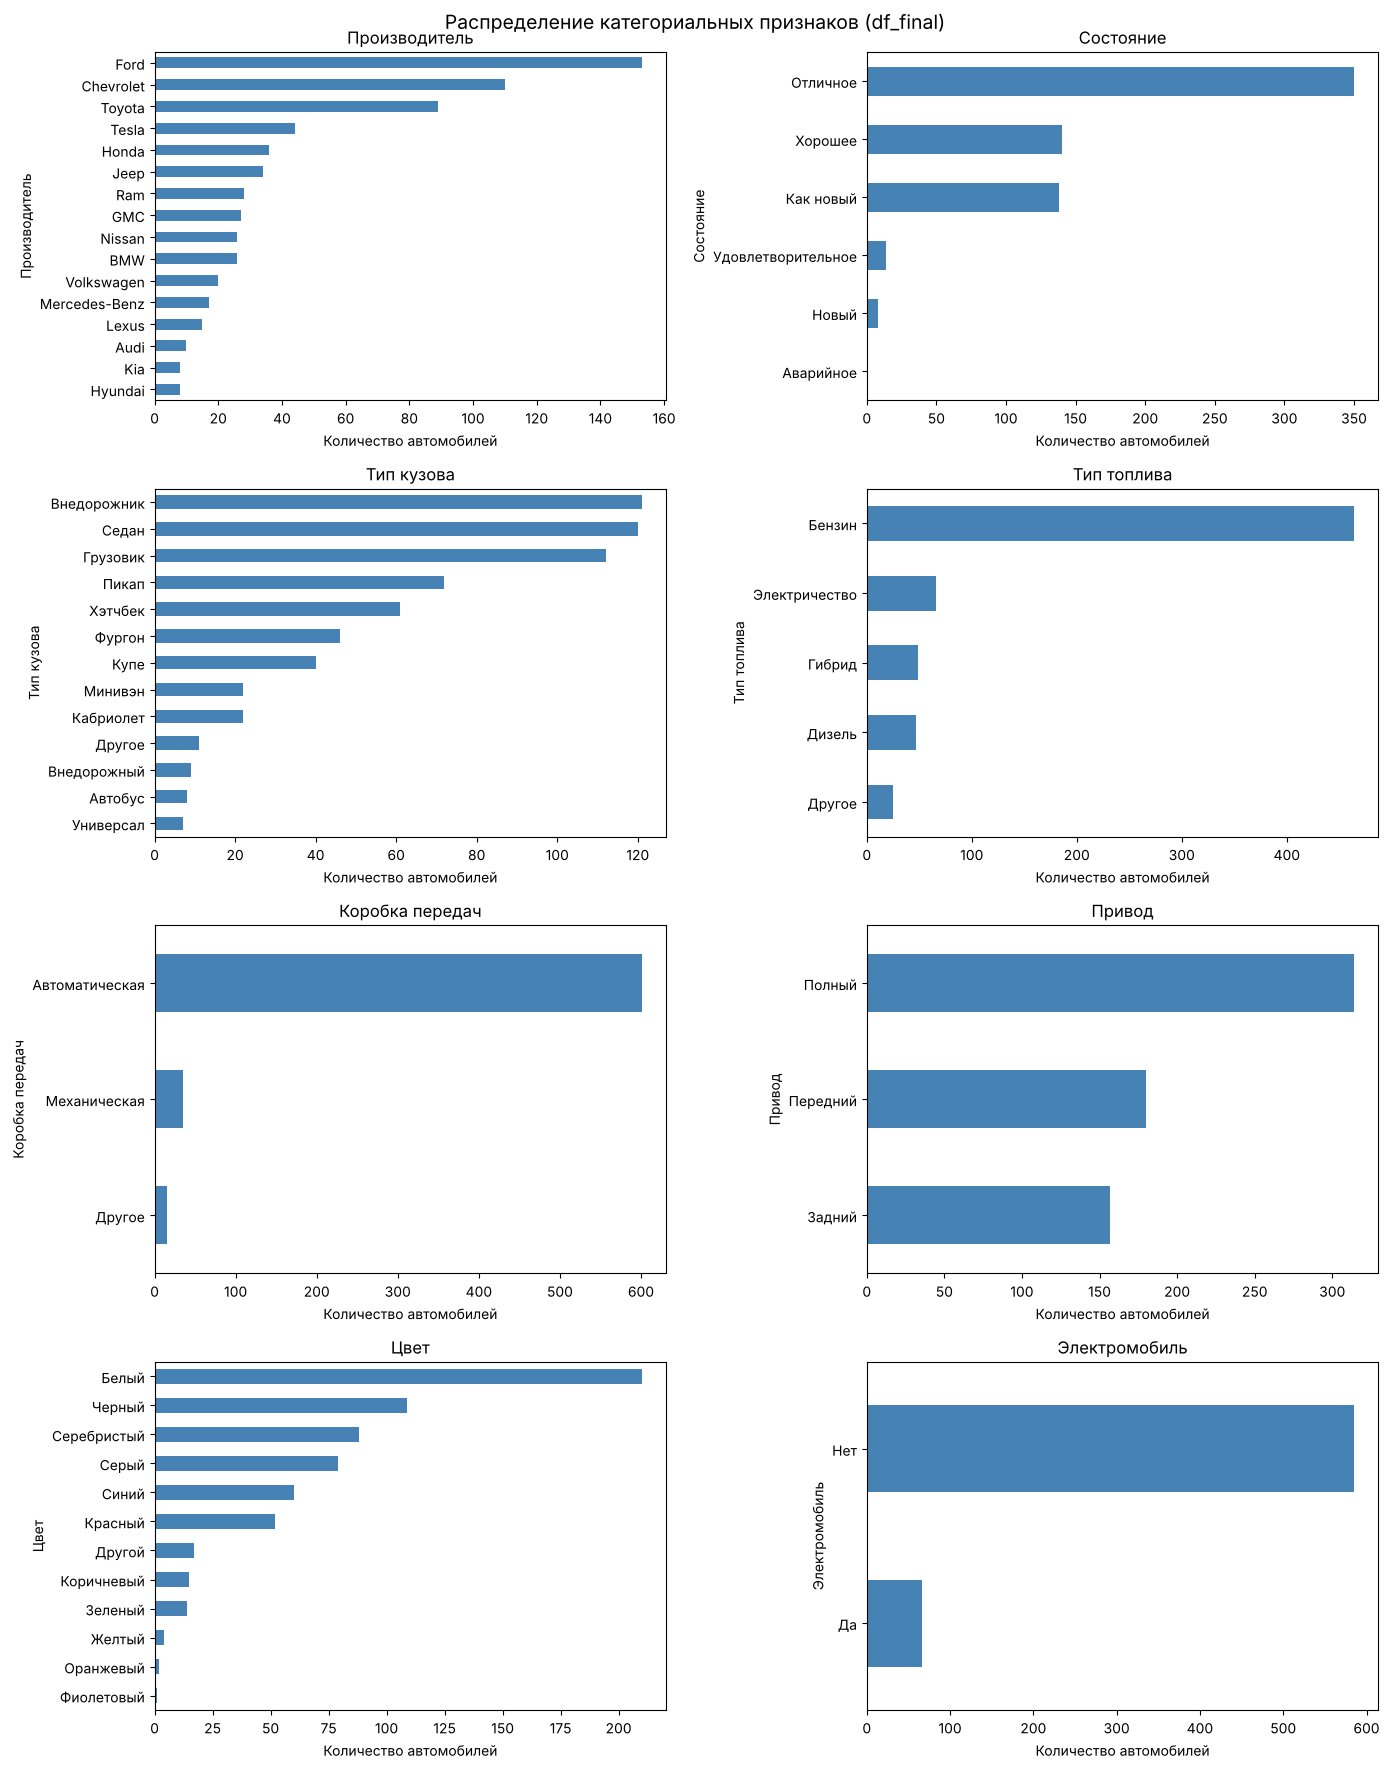

Производитель: уникальных 16, мода «Ford» — 153 (23.5%)
Состояние: уникальных 6, мода «Отличное» — 350 (53.8%)
Тип кузова: уникальных 13, мода «Внедорожник» — 121 (18.6%)
Тип топлива: уникальных 5, мода «Бензин» — 464 (71.3%)
Коробка передач: уникальных 3, мода «Автоматическая» — 601 (92.3%)
Привод: уникальных 3, мода «Полный» — 314 (48.2%)
Цвет: уникальных 12, мода «Белый» — 210 (32.3%)
Электромобиль: уникальных 2, мода «Нет» — 585 (89.9%)


In [11]:
cat_cols = ['Производитель', 'Состояние', 'Тип кузова', 'Тип топлива',
            'Коробка передач', 'Привод', 'Цвет', 'Электромобиль']

fig, axes = plt.subplots(4, 2, figsize=(14, 18))
for ax, col in zip(axes.flatten(), cat_cols):
    df_final[col].value_counts().sort_values().plot(kind='barh', ax=ax, color='steelblue')
    ax.set_title(col)
    ax.set_xlabel('Количество автомобилей')
plt.suptitle('Распределение категориальных признаков (df_final)', fontsize=14)
plt.tight_layout()
plt.show()

for col in cat_cols:
    vc = df_final[col].value_counts()
    print(f'{col}: уникальных {df_final[col].nunique()}, мода «{vc.index[0]}» '
          f'— {vc.iloc[0]} ({vc.iloc[0] / len(df_final) * 100:.1f}%)')

**Выводы по распределению категориальных признаков:**

- **Производитель** — 16 марок, лидирует Ford (153 машины, 23.5%), далее Chevrolet (110) и Toyota (89). Выборка смещена в сторону американских брендов, что ожидаемо для рынка США. Отдельно выделяется Tesla (44 машины) — это почти весь сегмент электромобилей.
- **Состояние** — преобладает «Отличное» (350 машин, 53.8%), затем «Хорошее» (140) и «Как новый» (138). Крайние категории представлены слабо: «Удовлетворительное» — 14, «Новый» — 8, «Аварийное» — всего 1 автомобиль. Выводы по трём редким категориям ненадёжны из-за малого числа наблюдений.
- **Тип кузова** — 13 категорий, распределение самое равномерное: «Внедорожник» (121, 18.6%), «Седан» (120) и «Грузовик» (112) идут практически вровень. Доминирования одного типа нет, поэтому вариативность этого признака наибольшая.
- **Тип топлива** — сильный перекос: бензин 464 машины (71.3%), остальные четыре категории делят оставшиеся 29%. Электричество (66), гибрид (49) и дизель (47) представлены сопоставимо.
- **Коробка передач** — 92.3% автоматов (601 машина). Механика (35) и «Другое» (15) — малочисленные группы, что типично для американского рынка.
- **Привод** — наиболее сбалансированный из трёхкатегорийных признаков: полный 314 (48.2%), передний 180, задний 157.
- **Цвет** — лидирует белый (210, 32.3%), затем чёрный (109) и серебристый (88). Яркие цвета (жёлтый, оранжевый, фиолетовый) единичны.
- **Электромобиль** — 66 машин из 651 (10.1%). Группа небольшая, но достаточная для статистического сравнения.

### 5.3. Связь цены с категориальными признаками: скрипичные графики

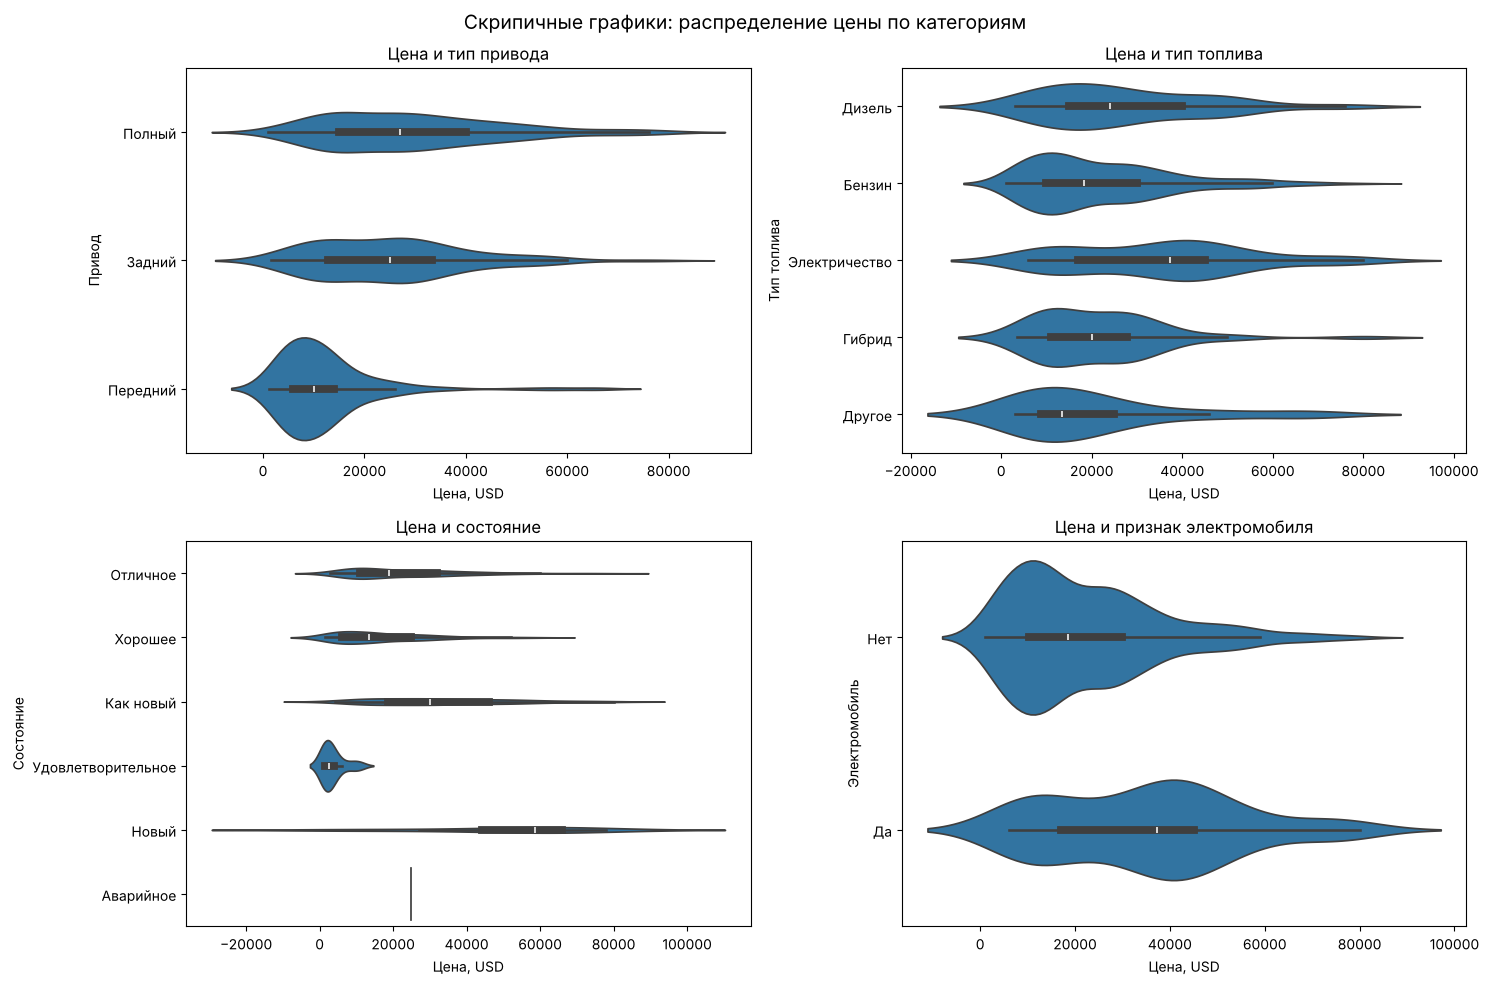

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.violinplot(data=df_final, x='Цена, USD', y='Привод', ax=axes[0, 0])
axes[0, 0].set_title('Цена и тип привода')

sns.violinplot(data=df_final, x='Цена, USD', y='Тип топлива', ax=axes[0, 1])
axes[0, 1].set_title('Цена и тип топлива')

sns.violinplot(data=df_final, x='Цена, USD', y='Состояние', ax=axes[1, 0])
axes[1, 0].set_title('Цена и состояние')

sns.violinplot(data=df_final, x='Цена, USD', y='Электромобиль', ax=axes[1, 1])
axes[1, 1].set_title('Цена и признак электромобиля')

plt.suptitle('Скрипичные графики: распределение цены по категориям', fontsize=14)
plt.tight_layout()
plt.show()

In [13]:
for col in ['Привод', 'Тип топлива', 'Состояние', 'Электромобиль']:
    print(df_final.groupby(col)['Цена, USD'].agg(['count', 'median', 'mean', 'std'])
          .round(0).sort_values('median', ascending=False), '\n')

          count   median     mean      std
Привод                                    
Полный      314  27000.0  29641.0  17554.0
Задний      157  25000.0  25251.0  15043.0
Передний    180   9996.0  12227.0  10542.0 

               count   median     mean      std
Тип топлива                                    
Электричество     66  37282.0  35346.0  19757.0
Дизель            47  24000.0  27211.0  17965.0
Гибрид            49  19995.0  21729.0  14132.0
Бензин           464  18248.0  22175.0  15954.0
Другое            25  13500.0  20264.0  18312.0 

                    count   median     mean      std
Состояние                                           
Новый                   8  58491.0  50922.0  24481.0
Как новый             138  29939.0  33522.0  18569.0
Аварийное               1  25000.0  25000.0      NaN
Отличное              350  18994.0  22938.0  15245.0
Хорошее               140  13500.0  16681.0  12615.0
Удовлетворительное     14   2600.0   3589.0   3067.0 

               coun

**Выводы по скрипичным графикам:**

- **Привод.** Самая выраженная связь с ценой среди всех категориальных признаков. Медиана у полного привода 26 999.5 USD, у заднего 25 000, у переднего всего 9 996 — почти втрое ниже. Скрипка переднего привода узкая и прижата к левому краю: это массовый сегмент недорогих легковых машин. У полного привода распределение широкое, с длинным правым хвостом — сюда попадают пикапы и внедорожники.
- **Тип топлива.** Электромобили заметно дороже остальных: медиана 37 282 против 18 248 у бензиновых, то есть вдвое. Дизель занимает промежуточное положение (24 000), гибрид близок к бензину (19 995). Скрипка бензина самая «толстая» в нижней части — это 71% выборки, преимущественно недорогие машины.
- **Состояние.** Медиана цены монотонно растёт вместе с улучшением состояния: «Удовлетворительное» 2 600 → «Хорошее» 13 500 → «Отличное» 18 994 → «Как новый» 29 939 → «Новый» 58 491. Это подтверждает порядковую природу признака и делает его хорошим кандидатом в предикторы. Оговорка: категории «Новый» (8 машин) и «Аварийное» (1 машина) малочисленны, их скрипки вырождаются, и выводы по ним ненадёжны — именно поэтому «Аварийное» с медианой 25 000 выбивается из общей монотонной картины.
- **Электромобиль.** Распределение цен у электромобилей сдвинуто вправо и заметно уже: медиана вдвое выше (37 282 против 18 500). Это ожидаемо — электромобили в выборке существенно новее и почти все представлены маркой Tesla.
- Общий вывод: три признака (`Привод`, `Состояние`, `Электромобиль`) показывают содержательную связь с ценой и будут рассмотрены как кандидаты в предикторы регрессии.

## 6. Описательные статистики

### 6.1. Целевой признак: Цена, USD

In [14]:
price = df_final['Цена, USD']

stats_price = pd.Series({
    'Количество наблюдений': price.count(),
    'Среднее арифметическое': price.mean(),
    'Медиана': price.median(),
    'Мода': price.mode()[0],
    'Минимум': price.min(),
    'Первый квартиль (Q1)': price.quantile(0.25),
    'Третий квартиль (Q3)': price.quantile(0.75),
    'Максимум': price.max(),
    'Размах': price.max() - price.min(),
    'Интерквартильный размах (IQR)': price.quantile(0.75) - price.quantile(0.25),
    'Дисперсия': price.var(),
    'Стандартное отклонение': price.std(),
    'Коэффициент вариации, %': price.std() / price.mean() * 100,
    'Коэффициент асимметрии': price.skew(),
    'Доля машин дороже среднего, %': (price > price.mean()).mean() * 100
})

# переводим в строки, чтобы pandas не показывал большие числа в экспоненциальной записи
stats_price.round(2).astype(str)

Количество наблюдений                   651.0
Среднее арифметическое               23767.13
Медиана                               19500.0
Мода                                  11500.0
Минимум                                1000.0
Первый квартиль (Q1)                  10500.0
Третий квартиль (Q3)                  33500.0
Максимум                              80000.0
Размах                                79000.0
Интерквартильный размах (IQR)         23000.0
Дисперсия                        287372948.47
Стандартное отклонение               16952.08
Коэффициент вариации, %                 71.33
Коэффициент асимметрии                   1.02
Доля машин дороже среднего, %           44.24
dtype: str

**Интерпретация описательных статистик целевого признака:**

- **Типичная цена.** Медиана составляет **19 500 USD**: половина автомобилей в выборке стоит дешевле этой суммы, половина дороже. Среднее арифметическое заметно выше — **23 767 USD**. Разрыв в 4 267 USD и коэффициент асимметрии **1.02** указывают на правостороннюю скошенность распределения. Для описания типичного автомобиля корректнее использовать медиану: она устойчива к выбросам, тогда как среднее тянется за дорогими машинами. Косвенное подтверждение — только 44.2% автомобилей стоят дороже средней цены, то есть среднее лежит выше «центра» выборки.
- **Самая частая цена** (мода) — **11 500 USD**, то есть массовый сегмент ещё дешевле медианы. Для непрерывного признака мода малоинформативна и указывает лишь на наиболее популярную круглую сумму в объявлениях.
- **Разброс.** Размах цен составляет **79 000 USD** (от 1 000 до 80 000) — это весь диапазон данных после удаления выбросов. Межквартильный размах равен **23 000 USD**: именно в интервале от 10 500 до 33 500 лежат центральные 50% автомобилей. IQR почти втрое меньше размаха, что ещё раз указывает на вытянутый правый хвост распределения.
- **Стандартное отклонение** равно **16 952 USD**: в среднем цена автомобиля отклоняется от средней примерно на эту сумму. Относительно среднего это 71% — коэффициент вариации очень высокий, выборка охватывает и бюджетные машины за 1 000 USD, и премиальный сегмент за 80 000.
- **Дисперсия** равна **287 372 948** — это квадрат стандартного отклонения, величина в «долларах в квадрате». Содержательно она не интерпретируется и используется только в расчётах.
- **Вывод для моделирования.** Высокая вариативность цены означает, что в данных есть что объяснять: если бы все машины стоили примерно одинаково, регрессия была бы бессмысленна. При этом скошенность распределения — предпосылка к тому, что качество линейной модели будет ограниченным.

### 6.2. Предикторы

In [15]:
# количественные предикторы
df_final[['Возраст автомобиля, лет', 'Пробег, миль', 'Количество цилиндров']].describe().round(2)

,"Возраст автомобиля, лет","Пробег, миль",Количество цилиндров
count,651.00,651.00,651.00
mean,8.24,89815.98,5.59
std,5.70,58968.60,2.46
min,0.00,10.00,0.00
25%,4.00,42000.00,4.00
50%,7.00,80384.00,6.00
75%,11.00,129345.50,8.00
max,31.00,260000.00,10.00


In [16]:
# категориальные предикторы
df_final.describe(include='object').T

,count,unique,top,freq
Производитель,651,16,Ford,153
Модель,651,444,f-150,16
Состояние,651,6,Отличное,350
Тип кузова,651,13,Внедорожник,121
Тип топлива,651,5,Бензин,464
Электромобиль,651,2,Нет,585
Коробка передач,651,3,Автоматическая,601
Привод,651,3,Полный,314
Цвет,651,12,Белый,210


**Интерпретация описательных статистик предикторов:**

**Количественные признаки** (считаем меры центральной тенденции, квартили и меры вариативности):

- **Пробег, миль.** Медианный автомобиль проехал **80 384 мили**, центральные 50% машин укладываются в диапазон от 42 000 до 129 346 миль (IQR = 87 346). Стандартное отклонение 58 969 миль сопоставимо с самой медианой — выборка охватывает и почти новые машины (минимум 10 миль), и сильно подержанные (до 260 000). Среднее (89 816) превышает медиану, что отражает умеренный правый скос.
- **Возраст автомобиля, лет.** Медиана **7 лет**, межквартильный размах тоже 7 лет (от 4 до 11). Среднее 8.24 выше медианы: преобладают относительно свежие автомобили, а старые машины образуют длинный правый хвост до 31 года. Стандартное отклонение 5.7 года.
- **Количество цилиндров.** Медиана **6**, типичные значения 4, 6 и 8. Минимум 0 относится к электромобилям, у которых двигатель внутреннего сгорания отсутствует. Признак дискретный, поэтому медиана и мода информативнее среднего: значения 5.59 цилиндра физически не существует.

**Категориальные признаки** (мера центральной тенденции — мода, мера вариативности — количество уникальных значений):

- **Производитель:** 16 уникальных марок, мода — **Ford** (153 машины, 23.5%).
- **Модель:** 444 уникальных значения — наибольшая вариативность в датасете. Из-за этого признак непригоден для кодирования и не будет использован в модели.
- **Состояние:** 6 градаций, мода — **«Отличное»** (350, 53.8%). Признак порядковый, поэтому для него осмысленна и медианная категория, которая также приходится на «Отличное».
- **Тип кузова:** 13 значений, мода — **«Внедорожник»** (121, 18.6%). Наибольшая вариативность среди пригодных для анализа категориальных признаков.
- **Тип топлива:** 5 значений, мода — **«Бензин»** (464, 71.3%). Сильная концентрация в одной категории.
- **Коробка передач:** 3 значения, мода — **«Автоматическая»** (601, 92.3%). Вариативность минимальная: выборка почти однородна по этому признаку, поэтому его объясняющая способность заведомо низкая.
- **Привод:** 3 значения, мода — **«Полный»** (314, 48.2%). Распределение наиболее равномерное.
- **Цвет:** 12 значений, мода — **«Белый»** (210, 32.3%).
- **Электромобиль:** бинарный признак, мода — **«Нет»** (585, 89.9%). Доля электромобилей 10.1%.

Для категориальных признаков не рассчитываются среднее, медиана и стандартное отклонение: их значения — текстовые метки, арифметические операции над ними не определены.

## 7. Перекодирование данных

Модель регрессии работает только с числами, поэтому категориальные признаки нужно перевести в числовой вид. Способ кодирования выбирается по типу признака.

### 7.1. One-Hot кодирование бинарного признака

In [17]:
df_encoded = pd.get_dummies(df_final, columns=['Электромобиль'], dtype=int)
print([col for col in df_encoded.columns if 'Электромобиль' in col])
df_encoded[['Электромобиль_Да', 'Электромобиль_Нет']].head()

['Электромобиль_Да', 'Электромобиль_Нет']


,Электромобиль_Да,Электромобиль_Нет
0,0,1
1,0,1
2,0,1
3,0,1
4,1,0


Дополнительно кодируем методом One-Hot номинальный признак `Привод`: его индикаторы понадобятся для регрессии (почему именно так — в выводах к разделу). Исходный столбец `Привод` сохраняем, он нужен для LabelEncoder в п. 7.2, поэтому индикаторы присоединяем через `pd.concat`.

In [18]:
drive_dummies = pd.get_dummies(df_encoded['Привод'], prefix='Привод', dtype=int)
df_encoded = pd.concat([df_encoded, drive_dummies], axis=1)
df_encoded[['Привод', 'Привод_Задний', 'Привод_Передний', 'Привод_Полный']].head()

,Привод,Привод_Задний,Привод_Передний,Привод_Полный
0,Полный,0,0,1
1,Полный,0,0,1
2,Задний,1,0,0
3,Полный,0,0,1
4,Задний,1,0,0


### 7.2. LabelEncoder для номинальных признаков

In [19]:
df_encoded['Привод_encoded'] = LabelEncoder().fit_transform(df_encoded['Привод'])
df_encoded['Коробка_encoded'] = LabelEncoder().fit_transform(df_encoded['Коробка передач'])
df_encoded['Топливо_encoded'] = LabelEncoder().fit_transform(df_encoded['Тип топлива'])

print('Привод:          ', dict(df_encoded.groupby('Привод')['Привод_encoded'].first()))
print('Коробка передач: ', dict(df_encoded.groupby('Коробка передач')['Коробка_encoded'].first()))
print('Тип топлива:     ', dict(df_encoded.groupby('Тип топлива')['Топливо_encoded'].first()))

Привод:           {'Задний': np.int64(0), 'Передний': np.int64(1), 'Полный': np.int64(2)}
Коробка передач:  {'Автоматическая': np.int64(0), 'Другое': np.int64(1), 'Механическая': np.int64(2)}
Тип топлива:      {'Бензин': np.int64(0), 'Гибрид': np.int64(1), 'Дизель': np.int64(2), 'Другое': np.int64(3), 'Электричество': np.int64(4)}


### 7.3. OrdinalEncoder для порядкового признака

In [20]:
order = [['Аварийное', 'Удовлетворительное', 'Хорошее', 'Отличное', 'Как новый', 'Новый']]

df_encoded['Состояние_encoded'] = OrdinalEncoder(categories=order).fit_transform(
    df_encoded[['Состояние']])

print(df_encoded.groupby('Состояние')['Состояние_encoded'].first().sort_values())

Состояние
Аварийное             0.0
Удовлетворительное    1.0
Хорошее               2.0
Отличное              3.0
Как новый             4.0
Новый                 5.0
Name: Состояние_encoded, dtype: float64


**Выводы по перекодированию:**

- **One-Hot кодирование** применено к бинарному признаку `Электромобиль`. Метод создаёт отдельный столбец-индикатор для каждой категории, получены `Электромобиль_Да` и `Электромобиль_Нет` со значениями 1/0. Параметр `dtype=int` задаёт именно числа, а не True/False. В дальнейшем используется только `Электромобиль_Да`: второй столбец полностью определяется первым, и включение обоих в регрессию привело бы к ловушке фиктивных переменных.
- **One-Hot кодирование `Привод`.** Получены три индикатора: `Привод_Задний`, `Привод_Передний`, `Привод_Полный`. В регрессию войдут только два последних, а задний привод станет базовой категорией, с которой сравниваются остальные (снова чтобы избежать ловушки фиктивных переменных).
- **LabelEncoder** применён к номинальным признакам `Привод`, `Коробка передач` и `Тип топлива`. Метод присваивает категориям целые числа по алфавиту: Задний = 0, Передний = 1, Полный = 2. Порядок здесь условный и содержательного смысла не имеет: нельзя сказать, что полный привод «в два раза больше» переднего. Это видно и по данным: медианная цена по кодам 0 → 1 → 2 идёт как 25 000 → 9 996 → 27 000, то есть не растёт и не убывает монотонно. Поэтому коэффициент регрессии при `Привод_encoded` нельзя было бы интерпретировать, и в модель привод включается через индикаторы One-Hot.
- **OrdinalEncoder** применён к порядковому признаку `Состояние` с явно заданной последовательностью: Аварийное = 0, Удовлетворительное = 1, Хорошее = 2, Отличное = 3, Как новый = 4, Новый = 5. В отличие от LabelEncoder здесь числовой порядок отражает реальное улучшение состояния автомобиля, что подтверждается монотонным ростом медианной цены по этим категориям (см. раздел 5.3). Если бы порядок не был задан явно, кодировка пошла бы по алфавиту и смысл был бы потерян.
- Признаки `Производитель` (16 категорий) и `Модель` (444 категории) не кодировались. Присвоение им порядковых номеров создало бы ложную числовую шкалу, а One-Hot кодирование `Модели` добавило бы 444 столбца при 651 наблюдении, что заведомо привело бы к переобучению.
- Результат сохранён в датафрейм **df_encoded**.

## 8. Корреляционный анализ

### 8.1. Парная корреляция: цена и пробег

Корреляция Пирсона : -0.599
Корреляция Спирмена: -0.642


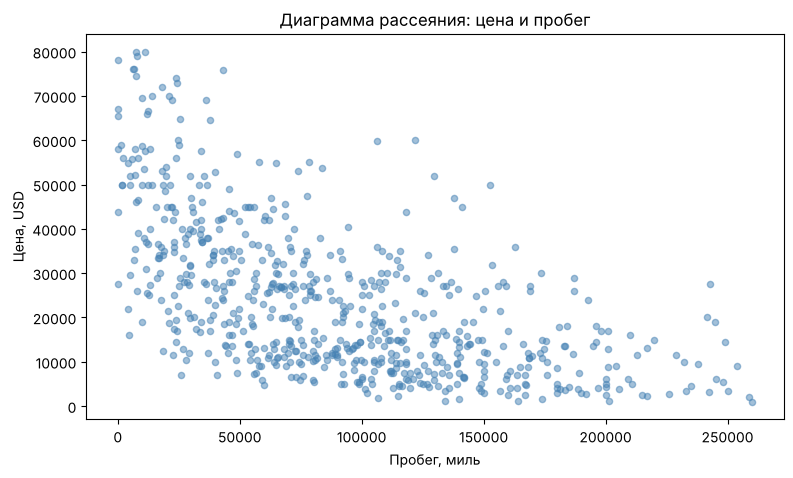

In [21]:
pearson = df_encoded['Цена, USD'].corr(df_encoded['Пробег, миль'])
spearman = df_encoded['Цена, USD'].corr(df_encoded['Пробег, миль'], method='spearman')

print('Корреляция Пирсона :', round(pearson, 3))
print('Корреляция Спирмена:', round(spearman, 3))

df_encoded.plot(x='Пробег, миль', y='Цена, USD', kind='scatter',
                alpha=0.5, figsize=(9, 5), color='steelblue',
                title='Диаграмма рассеяния: цена и пробег')
plt.show()

**Интерпретация коэффициента корреляции между ценой и пробегом:**

- **Направление связи обратное.** Оба коэффициента отрицательны: чем больше пробег автомобиля, тем ниже его цена. Это согласуется с содержательными ожиданиями — пробег отражает износ машины.
- **Сила связи умеренная, близкая к сильной.** Коэффициент Пирсона равен **−0.599**, по модулю он попадает в диапазон 0.5–0.7, что трактуется как умеренная линейная взаимосвязь.
- **Тип связи.** Коэффициент Спирмена (**−0.642**) по модулю выше, чем коэффициент Пирсона (−0.599). Это означает, что монотонная связь выражена сильнее линейной: цена убывает с ростом пробега не строго по прямой, а по кривой. Содержательно это объясняется тем, что первые десятки тысяч миль обесценивают автомобиль существенно сильнее, чем последующие. На диаграмме рассеяния видна именно изогнутая форма облака точек, а не прямая полоса.
- **Корреляция не означает причинно-следственную связь.** Мы не можем утверждать, что именно пробег является причиной снижения цены. Оба признака связаны с возрастом автомобиля (корреляция пробега и возраста равна 0.583), который может выступать общей причиной для обоих. Корректная формулировка — «между пробегом и ценой существует умеренная обратная связь», а не «пробег влияет на цену».

### 8.2. Корреляционная матрица

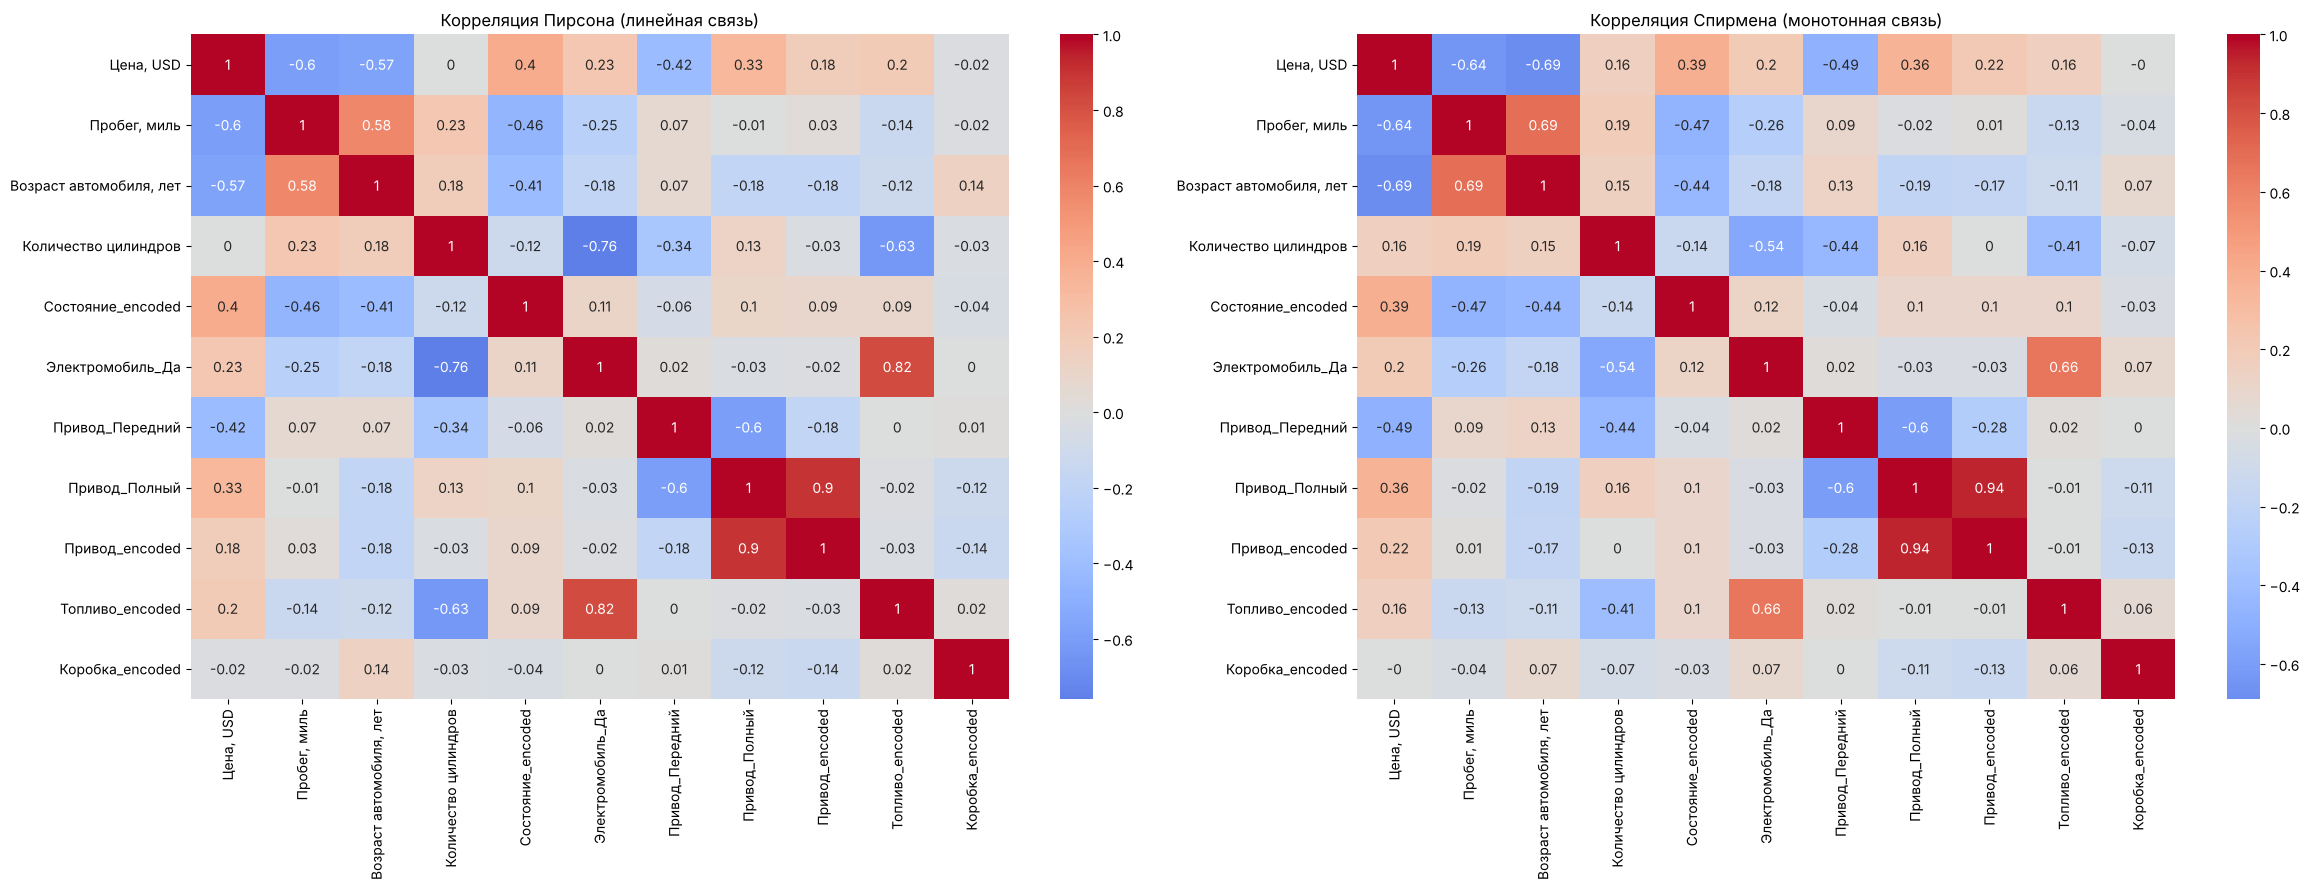

In [22]:
corr_cols = ['Цена, USD', 'Пробег, миль', 'Возраст автомобиля, лет', 'Количество цилиндров',
             'Состояние_encoded', 'Электромобиль_Да', 'Привод_Передний', 'Привод_Полный',
             'Привод_encoded', 'Топливо_encoded', 'Коробка_encoded']

corr_pearson = df_encoded[corr_cols].corr().round(2)
corr_spearman = df_encoded[corr_cols].corr(method='spearman').round(2)

fig, axes = plt.subplots(1, 2, figsize=(24, 9))
sns.heatmap(corr_pearson, annot=True, cmap='coolwarm', center=0, ax=axes[0])
axes[0].set_title('Корреляция Пирсона (линейная связь)')
sns.heatmap(corr_spearman, annot=True, cmap='coolwarm', center=0, ax=axes[1])
axes[1].set_title('Корреляция Спирмена (монотонная связь)')
plt.tight_layout()
plt.show()

### 8.3. Топ-5 признаков по силе связи с ценой

In [23]:
top_spearman = (corr_spearman['Цена, USD'].drop('Цена, USD')
                .sort_values(key=abs, ascending=False))

print('ТОП-5 по Спирмену (монотонная связь, все признаки):')
print(top_spearman.head(5), '\n')

# Пирсон интерпретируется только между количественными признаками
quant = ['Пробег, миль', 'Возраст автомобиля, лет', 'Количество цилиндров']
print('Пирсон, только количественные предикторы (линейная связь):')
print(corr_pearson.loc[quant, 'Цена, USD'].sort_values(key=abs, ascending=False))

ТОП-5 по Спирмену (монотонная связь, все признаки):
Возраст автомобиля, лет   -0.69
Пробег, миль              -0.64
Привод_Передний           -0.49
Состояние_encoded          0.39
Привод_Полный              0.36
Name: Цена, USD, dtype: float64 

Пирсон, только количественные предикторы (линейная связь):
Пробег, миль              -0.60
Возраст автомобиля, лет   -0.57
Количество цилиндров       0.00
Name: Цена, USD, dtype: float64


**Выводы по корреляционному анализу:**

Построены две матрицы: Пирсона (измеряет линейную связь) и Спирмена (монотонную). Признаки `Производитель` и `Модель` в матрицу не включены, так как не имеют осмысленной числовой шкалы.

**Какой коэффициент читаем.** Корреляция Пирсона интерпретируется только между количественными признаками, а корреляция Спирмена — между количественными и категориальными. В матрице есть закодированные категориальные признаки (`Состояние_encoded`, `Электромобиль_Да`, индикаторы привода и др.), поэтому топ-5 по силе связи с ценой отбираем **по Спирмену**. Пирсон используется только для количественных признаков. Сортировка выполнена по модулю коэффициента (`key=abs`), поскольку сила связи не зависит от её направления.

**Топ-5 признаков по силе связи с ценой (по Спирмену):**

1. **Возраст автомобиля, лет** — −0.69: умеренная, близкая к сильной, обратная монотонная связь. Чем старше автомобиль, тем ниже цена.
2. **Пробег, миль** — −0.64: умеренная, близкая к сильной, обратная монотонная связь. Чем больше пробег, тем ниже цена.
3. **Привод_Передний** — −0.49: умеренная обратная связь. Если у автомобиля передний привод (1), это может понизить его стоимость.
4. **Состояние_encoded** — 0.39: умеренная прямая монотонная связь. Чем лучше состояние, тем выше цена.
5. **Привод_Полный** — 0.36: умеренная прямая связь. Если у автомобиля полный привод (1), это может повысить его стоимость.

Сразу за пятёркой идут `Привод_encoded` (0.22) и `Электромобиль_Да` (0.20) — слабые прямые связи. `Привод_encoded` дублирует уже вошедшие индикаторы привода.

**Количественные признаки по Пирсону.** Пробег −0.60 и возраст −0.57 — умеренная, близкая к сильной, обратная линейная связь. У обоих Спирмен по модулю больше Пирсона, значит связь скорее нелинейная: цена падает быстрее в первые годы и первые десятки тысяч миль.

**Мультиколлинеарность.** В матрице видны сильные связи между самими предикторами:

- `Количество цилиндров` ~ `Электромобиль_Да`: **−0.76**;
- `Электромобиль_Да` ~ `Топливо_encoded`: **0.82**;
- `Количество цилиндров` ~ `Топливо_encoded`: −0.63;
- `Привод_Передний` ~ `Привод_Полный`: −0.60;
- `Пробег, миль` ~ `Возраст автомобиля, лет`: 0.58.

Первые три объясняются содержательно: у всех электромобилей ровно ноль цилиндров, а признак топлива и признак электромобиля описывают почти одно и то же. Связь двух индикаторов привода ожидаема: автомобиль не может быть одновременно переднеприводным и полноприводным. Проблемой это не является, так как третья категория (задний привод) исключена и служит базовой. Сильно связанные признаки нужно учитывать при отборе предикторов: их одновременное включение делает коэффициенты неустойчивыми и затрудняет интерпретацию.

**Отдельный случай — `Количество цилиндров`.** Корреляция Пирсона с ценой практически нулевая (0.00), Спирмена — слабая (0.16). Причина в том, что в данных смешаны две группы дорогих машин с противоположными значениями: мощные бензиновые с 8 цилиндрами и электромобили с нулём цилиндров. В линейном коэффициенте эти эффекты гасят друг друга.

**`Коробка_encoded`** имеет корреляцию −0.002 по Спирмену, то есть монотонная связь с ценой практически отсутствует. Это ожидаемо: 92.3% выборки — автоматы, признак почти не варьируется.

## 9. Масштабирование данных

In [24]:
quant_cols = ['Пробег, миль', 'Возраст автомобиля, лет', 'Количество цилиндров']

print('ДО масштабирования:')
print(df_encoded[quant_cols].agg(['mean', 'std']).round(2), '\n')

scaler = StandardScaler()
df_scaled = df_encoded.copy()
df_scaled[quant_cols] = scaler.fit_transform(df_encoded[quant_cols])

print('ПОСЛЕ масштабирования:')
print(df_scaled[quant_cols].agg(['mean', 'std']).round(3))

ДО масштабирования:
      Пробег, миль  Возраст автомобиля, лет  Количество цилиндров
mean      89815.98                     8.24                  5.59
std       58968.60                     5.70                  2.46 

ПОСЛЕ масштабирования:
      Пробег, миль  Возраст автомобиля, лет  Количество цилиндров
mean         0.000                   -0.000                 0.000
std          1.001                    1.001                 1.001


**Выводы по масштабированию:**

- Все количественные предикторы (`Пробег, миль`, `Возраст автомобиля, лет`, `Количество цилиндров`) приведены к единому масштабу с помощью `StandardScaler`. Преобразование вычитает из каждого значения среднее по признаку и делит на стандартное отклонение, поэтому у нормализованного признака среднее становится равным 0, а стандартное отклонение — 1. Расчёт подтверждает: после преобразования все три признака имеют среднее 0.000 и стандартное отклонение 1.001. Отличие от 1 в третьем знаке связано с тем, что `StandardScaler` делит на смещённое стандартное отклонение (на n), а `std()` в pandas считает несмещённое (на n − 1).
- **Зачем это нужно.** Исходные признаки измерены в несопоставимых единицах: пробег исчисляется десятками тысяч миль (стандартное отклонение 58 969), а возраст — единицами лет (стандартное отклонение 5.70). Без масштабирования коэффициенты регрессии нельзя сравнивать между собой: малый по модулю коэффициент при пробеге не означал бы слабого вклада признака, а лишь отражал бы крупную единицу измерения. После нормализации коэффициенты выражены в одинаковых единицах (изменение цены при сдвиге признака на одно стандартное отклонение), и их можно сопоставлять напрямую.
- `Количество цилиндров` нормализовано вместе с остальными количественными признаками, но в регрессию не войдёт из-за мультиколлинеарности с признаком электромобиля (см. раздел 10.1).
- **Что не масштабируется.** Целевая переменная `Цена, USD` оставлена в долларах, чтобы коэффициенты и ошибки модели читались в исходных единицах. Закодированные категориальные признаки (`Состояние_encoded`, `Электромобиль_Да`, `Привод_Передний`, `Привод_Полный`) тоже оставлены без изменений: их значения — метки категорий, а не измеренные величины. Масштабирование меток лишило бы коэффициенты понятной интерпретации вида «если признак равен 1».
- Результат сохранён в датафрейм **df_scaled**.

## 10. Линейная регрессия

### 10.1. Описание модели

Мы хотим построить модель, которая предсказывает **цену подержанного автомобиля в долларах** по его пробегу, возрасту, техническому состоянию, типу привода и тому, является ли он электромобилем.

Целевая переменная `Цена, USD` количественная, поэтому используется линейная регрессия (подтверждено ассистентом).

**Отбор предикторов.** В модель включены все пять признаков из топ-5 по Спирмену (раздел 8.3) и признак `Электромобиль_Да`, который идёт следом:

- `Пробег, миль` и `Возраст автомобиля, лет` — нормализованные количественные признаки;
- `Состояние_encoded` — порядковый признак, закодированный OrdinalEncoder;
- `Привод_Передний` и `Привод_Полный` — индикаторы One-Hot, базовая категория — задний привод;
- `Электромобиль_Да` — бинарный индикатор.

Что не вошло и почему:

- `Привод_encoded` не используется: коды LabelEncoder присвоены по алфавиту и не отражают порядка цен (25 000 → 9 996 → 27 000), коэффициент при таком признаке не интерпретируется. Привод представлен в модели индикаторами One-Hot.
- `Топливо_encoded` исключён по той же причине (номинальный признак с алфавитными кодами), к тому же он почти дублирует `Электромобиль_Да` (корреляция 0.82).
- `Количество цилиндров` исключён из-за мультиколлинеарности: корреляция с `Электромобиль_Да` равна **−0.76**, так как у всех электромобилей ровно ноль цилиндров. При одновременном включении обоих признаков коэффициенты стали бы неустойчивыми и неинтерпретируемыми.

**Проверка достаточности данных.** В модели 6 предикторов при 651 наблюдении, то есть около 108 наблюдений на предиктор. Требование «минимум 100 наблюдений на предиктор» выполнено.

Итоговая форма модели:

$$\text{Цена} = w_0 + w_1 \cdot z(\text{Пробег}) + w_2 \cdot z(\text{Возраст}) + w_3 \cdot \text{Состояние} + w_4 \cdot \text{Электромобиль} + w_5 \cdot \text{Передний} + w_6 \cdot \text{Полный}$$

где $z(\cdot)$ — нормализованное значение признака после `StandardScaler`.

### 10.2. Деление выборки на тренировочную и тестовую

In [25]:
X = df_scaled[['Пробег, миль', 'Возраст автомобиля, лет', 'Состояние_encoded',
               'Электромобиль_Да', 'Привод_Передний', 'Привод_Полный']]
Y = df_scaled['Цена, USD']

X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

print('Тренировочная выборка:', X_train.shape)
print('Тестовая выборка:     ', X_test.shape)

Тренировочная выборка: (520, 6)
Тестовая выборка:      (131, 6)


Выборка разделена в соотношении 80 на 20: 520 автомобилей для обучения и 131 для проверки качества. Тренировочная выборка нужна для поиска коэффициентов методом наименьших квадратов, тестовая — для честной оценки качества на данных, которых модель не видела. Параметр `random_state=42` фиксирует случайное разбиение, чтобы результат воспроизводился при повторном запуске.

### 10.3. Обучение модели и уравнение

In [26]:
model = LinearRegression().fit(X_train, y_train)

print('Свободный коэффициент w0:', round(model.intercept_, 2))
print()
for name, w in zip(X.columns, model.coef_):
    print(f'{name:28} {w:>12.2f}')

Свободный коэффициент w0: 19722.85

Пробег, миль                     -5755.64
Возраст автомобиля, лет          -5118.15
Состояние_encoded                 1958.15
Электромобиль_Да                  5368.16
Привод_Передний                 -12290.69
Привод_Полный                     2031.34


### Уравнение обученной модели

$$\text{Цена} = 19722.85 - 5755.64 \cdot z(\text{Пробег}) - 5118.15 \cdot z(\text{Возраст}) + 1958.15 \cdot \text{Состояние} + 5368.16 \cdot \text{Электромобиль} - 12290.69 \cdot \text{Передний} + 2031.34 \cdot \text{Полный}$$

### 10.4. Интерпретация параметров модели

- **$w_0 = 19\,722.85$.** Если все предикторы равны нулю, модель предсказывает цену 19 723 доллара. Это автомобиль со средним пробегом и средним возрастом (ноль у нормализованного признака соответствует среднему значению), в аварийном состоянии (код 0), не электромобиль, с задним приводом (базовая категория). Такое сочетание в данных практически не встречается (аварийный автомобиль в выборке всего один), поэтому свободный коэффициент интерпретируется условно и служит точкой отсчёта.
- **$w_1 = -5\,755.64$.** При увеличении пробега на одно стандартное отклонение (58 969 миль) цена автомобиля снижается в среднем на 5 756 долларов при неизменных значениях остальных факторов. В пересчёте на исходные единицы это примерно **98 долларов на каждую тысячу миль** пробега.
- **$w_2 = -5\,118.15$.** При увеличении возраста на одно стандартное отклонение (5.7 года) цена снижается в среднем на 5 118 долларов при прочих равных. В пересчёте — около **899 долларов за каждый дополнительный год** эксплуатации.
- **$w_3 = 1\,958.15$.** При улучшении состояния на одну ступень (например, с «Хорошего» на «Отличное») цена возрастает в среднем на 1 958 долларов при прочих равных. Интерпретация корректна, потому что признак закодирован `OrdinalEncoder` с осмысленным порядком категорий.
- **$w_4 = 5\,368.16$.** Если автомобиль — электромобиль (признак равен 1), его цена в среднем на 5 368 долларов выше, чем у автомобиля с двигателем внутреннего сгорания при прочих равных.
- **$w_5 = -12\,290.69$.** Если у автомобиля передний привод (признак равен 1), его цена в среднем на 12 291 доллар ниже, чем у автомобиля с задним приводом (базовая категория) при прочих равных. Это самый большой по модулю коэффициент модели: переднеприводные машины — массовый сегмент недорогих легковых автомобилей.
- **$w_6 = 2\,031.34$.** Если у автомобиля полный привод (признак равен 1), его цена в среднем на 2 031 доллар выше, чем у автомобиля с задним приводом при прочих равных.

**Сравнение вкладов.** Коэффициенты при пробеге и возрасте можно сравнивать между собой, так как оба признака нормализованы и измеряются в стандартных отклонениях: вклад пробега (−5 756) немного больше вклада возраста (−5 118), и оба работают на снижение цены, что соответствует экономическому смыслу износа. Коэффициенты при индикаторах читаются как разница в цене между категориями. Самый сильный разрыв — между передним и задним приводом.

### 10.5. Метрики качества модели

In [27]:
y_pred = model.predict(X_test)

print('R2  =', round(r2_score(y_test, y_pred), 3))
print('MSE =', round(mean_squared_error(y_test, y_pred), 2))
print('RMSE=', round(mean_squared_error(y_test, y_pred) ** 0.5, 2))
print('MAE =', round(mean_absolute_error(y_test, y_pred), 2))
print()
print('Средняя цена в тестовой выборке:', round(y_test.mean(), 2))
print('MAE в процентах от средней цены:',
      round(mean_absolute_error(y_test, y_pred) / y_test.mean() * 100, 1), '%')

R2  = 0.613
MSE = 103084860.6
RMSE= 10153.07
MAE = 8110.01

Средняя цена в тестовой выборке: 24596.49
MAE в процентах от средней цены: 33.0 %


In [28]:
# для сравнения: та же модель, но привод одним столбцом LabelEncoder вместо индикаторов One-Hot
X_le = df_scaled[['Пробег, миль', 'Возраст автомобиля, лет', 'Состояние_encoded',
                  'Электромобиль_Да', 'Привод_encoded']]
X_train_le, X_test_le, y_train_le, y_test_le = train_test_split(X_le, Y, test_size=0.2, random_state=42)
y_pred_le = LinearRegression().fit(X_train_le, y_train_le).predict(X_test_le)

print('Привод через LabelEncoder: R2 =', round(r2_score(y_test_le, y_pred_le), 3),
      '| MAE =', round(mean_absolute_error(y_test_le, y_pred_le), 2))
print('Привод через One-Hot:      R2 =', round(r2_score(y_test, y_pred), 3),
      '| MAE =', round(mean_absolute_error(y_test, y_pred), 2))

Привод через LabelEncoder: R2 = 0.455 | MAE = 9773.51
Привод через One-Hot:      R2 = 0.613 | MAE = 8110.01


**Интерпретация метрик качества обученной модели:**

- **Коэффициент детерминации $R^2 = 0.613$.** Модель объясняет 61.3% разброса цен автомобилей. Оставшиеся 38.7% вариации описываются факторами, которые в модель не вошли: маркой и моделью автомобиля, комплектацией, региональными различиями рынка, историей обслуживания. Метрика принимает значения от 0 до 1: 1 означает идеальное предсказание, 0 — качество на уровне подстановки среднего значения. Значение 0.613 означает, что модель заметно лучше такой подстановки, но далека от точной.
- **Средняя абсолютная ошибка $MAE = 8\,110.01$ доллара.** В среднем предсказание модели расходится с реальной ценой на 8 110 долларов. При средней цене автомобиля в тестовой выборке 24 596 долларов это около 33%. Ошибка велика, и для точной оценки конкретного автомобиля модель не подходит. MAE измеряется в тех же единицах, что и целевая переменная, поэтому именно её удобно обсуждать содержательно.
- **Среднеквадратичная ошибка $MSE = 103\,084\,860.60$.** Метрика измеряется в квадратах долларов, поэтому её абсолютное значение содержательно не интерпретируется и используется только для сравнения моделей между собой. MSE сильнее штрафует крупные промахи, чем MAE. Корень из неё, $RMSE = 10\,153.07$ доллара, возвращает величину в исходные единицы. RMSE больше MAE: среди наблюдений есть отдельные автомобили с особенно большой ошибкой, вероятно, из премиального сегмента.
- **Роль кодирования привода.** Вариант модели, где привод входит одним столбцом `Привод_encoded` с алфавитными кодами, даёт (расчёт выше) $R^2 = 0.455$ и $MAE = 9\,774$. Замена его на индикаторы One-Hot подняла $R^2$ до 0.613 и снизила ошибку на 1 664 доллара: LabelEncoder навязывал ценам несуществующий порядок «задний < передний < полный».
- **Общий вывод.** Модель улавливает основные закономерности рынка: цена снижается с ростом пробега и возраста, растёт с улучшением состояния, у электромобилей есть надбавка, а переднеприводные машины заметно дешевле. Все коэффициенты имеют ожидаемые знаки, то есть модель содержательно непротиворечива. Однако точности для практической оценки стоимости конкретного автомобиля недостаточно. Для повышения качества потребовалось бы добавить марку и модель автомобиля, что требует более сложных методов работы с признаками, имеющими сотни категорий.

## 11. Тестирование гипотез

В этом разделе реализованы все изученные тесты: критерий Шапиро-Уилка и семь статистических тестов. Для каждого теста приводится словесная формулировка с проверкой предпосылок, математическая запись гипотез и интерпретация результата.

Основной уровень значимости $\alpha = 0.05$, дополнительно результат проверяется на уровнях 0.01 и 0.10. Решение принимается по p-value:

- если $p < \alpha$ — нулевая гипотеза отвергается;
- если $p > \alpha$ — нулевая гипотеза не отвергается.

### 11.1. Критерий Шапиро-Уилка

**Словесная формулировка.** Мы хотим проверить, можно ли считать, что цена автомобиля, его пробег и возраст распределены нормально. Этот тест проводится первым, потому что от его результата зависит применимость остальных тестов: параметрические тесты (z-тест, t-тесты) требуют нормальности, непараметрические — нет.

**Гипотезы.**

$H_0: X \sim N(\mu, \sigma^2)$ — признак распределён нормально

$H_1: X \nsim N(\mu, \sigma^2)$ — признак распределён не нормально

In [29]:
for col in ['Цена, USD', 'Пробег, миль', 'Возраст автомобиля, лет']:
    res = stats.shapiro(df_final[col])
    print(f'{col:28} W = {res[0]:.4f}, p-value = {res[1]:.4e}')

res_ln = stats.shapiro(np.log(df_final['Цена, USD']))
print(f'{"ln(Цена, USD)":28} W = {res_ln[0]:.4f}, p-value = {res_ln[1]:.4e}')

Цена, USD                    W = 0.9148, p-value = 1.1591e-18
Пробег, миль                 W = 0.9585, p-value = 1.3524e-12
Возраст автомобиля, лет      W = 0.9023, p-value = 5.6986e-20
ln(Цена, USD)                W = 0.9717, p-value = 6.7427e-10


**Интерпретация.**

Во всех трёх случаях p-value многократно меньше 0.01 (порядок $10^{-12}$ и ниже), поэтому нулевая гипотеза отвергается на любом разумном уровне значимости — 1%, 5% и 10%. Ни один из количественных признаков не распределён нормально. Это ожидаемо: все три имеют выраженную правостороннюю скошенность (коэффициенты асимметрии 1.02, 0.60 и 1.21 соответственно, см. раздел 5.1).

Дополнительно проверено логарифмирование цены: статистика $W$ растёт с 0.9148 до 0.9717, то есть распределение становится ближе к нормальному, но формально нормальность не достигается и после преобразования.

**Следствие для дальнейших тестов.** Формально предпосылка нормальности нарушена для всех параметрических тестов. Однако объём выборки велик (651 наблюдение, а в каждой сравниваемой подгруппе не менее 35), поэтому по центральной предельной теореме выборочное среднее распределено приближённо нормально, и z-тест с t-тестами остаются применимыми. Там, где форма распределения сильно асимметрична, результат дополнительно проверяется непараметрическим критерием Манна-Уитни.

### 11.2. Z-тест для среднего

**Словесная формулировка.** Мы хотим проверить гипотезу о том, что средняя цена подержанного автомобиля на рынке равна 25 000 долларов, если считать, что дисперсия генеральной совокупности совпадает с выборочной.

**Проверка предпосылок:** признак условно нормален (по ЦПТ при большой выборке), дисперсия генеральной совокупности считается известной, количество наблюдений 651 — заметно больше 30. Предпосылки выполнены.

**Гипотезы.**

$H_0: \mu_{\text{цена}} = 25000$

$H_1: \mu_{\text{цена}} \neq 25000$

In [30]:
z_stat, p_value = ztest(df_final['Цена, USD'], value=25000, alternative='two-sided')

print('Выборочное среднее:', round(df_final['Цена, USD'].mean(), 2))
print(f'z-статистика = {z_stat:.4f}')
print(f'p-value      = {p_value:.4f}')

Выборочное среднее: 23767.13
z-статистика = -1.8556
p-value      = 0.0635


**Интерпретация.**

Выборочное среднее равно 23 767.13 доллара, p-value = **0.0635**.

- На уровне значимости **1%**: $p = 0.0635 > 0.01$ — нулевая гипотеза не отвергается.
- На уровне значимости **5%**: $p = 0.0635 > 0.05$ — нулевая гипотеза не отвергается.
- На уровне значимости **10%**: $p = 0.0635 < 0.10$ — нулевая гипотеза отвергается.

Результат пограничный: на стандартном уровне 5% данные не дают достаточных оснований утверждать, что средняя цена на рынке отличается от 25 000 долларов, однако на уровне 10% такое отличие признаётся значимым. Наблюдаемое отклонение выборочного среднего от 25 000 находится на границе статистической значимости, и вывод зависит от выбранного уровня — этот случай следует оговаривать явно, а не приводить единственный ответ.

### 11.3. Одновыборочный t-тест

**Словесная формулировка.** Мы хотим проверить гипотезу о том, что средняя цена подержанного автомобиля превышает 22 000 долларов. В отличие от z-теста здесь не предполагается, что дисперсия генеральной совокупности известна — она оценивается по выборке. Альтернативная гипотеза правосторонняя.

**Проверка предпосылок:** признак условно нормален по ЦПТ при 651 наблюдении. Предпосылка выполнена.

**Гипотезы.**

$H_0: \mu_{\text{цена}} = 22000$

$H_1: \mu_{\text{цена}} > 22000$

In [31]:
t_stat, p_value = stats.ttest_1samp(df_final['Цена, USD'],
                                    popmean=22000,
                                    alternative='greater')

print(f't-статистика = {t_stat:.4f}')
print(f'p-value      = {p_value:.4f}')

# для сравнения с z-тестом: тот же тест против 25 000, двусторонний
t_25, p_25 = stats.ttest_1samp(df_final['Цена, USD'], popmean=25000, alternative='two-sided')
print(f'\nДля сравнения: H0: mu = 25000 → t = {t_25:.4f}, p-value = {p_25:.4f}')

t-статистика = 2.6597
p-value      = 0.0040

Для сравнения: H0: mu = 25000 → t = -1.8556, p-value = 0.0640


**Интерпретация.**

p-value = **0.0040**, что меньше 0.01. Нулевая гипотеза отвергается на всех трёх уровнях значимости — 10%, 5% и 1%. Средняя цена подержанного автомобиля статистически значимо превышает 22 000 долларов.

Отдельно отметим связь с предыдущим тестом: при проверке того же набора данных против значения 25 000 долларов двусторонний t-тест даёт p-value 0.0640, что практически совпадает с результатом z-теста (0.0635). Это ожидаемо — при большом объёме выборки распределение Стьюдента приближается к стандартному нормальному, и оба теста дают почти одинаковый результат, несмотря на разные предпосылки о дисперсии.

### 11.4. Парный t-тест — неприменим

**Словесная формулировка.** Парный t-тест сравнивает средние двух **связанных** выборок, то есть двух измерений, сделанных на одних и тех же объектах. Классические примеры: цена автомобиля до и после ремонта, показатели региона до и после введения субсидий, результаты одной группы респондентов до и после обучения.

**Гипотезы (если бы тест был применим).**

$H_0: \mu_{\text{до}} = \mu_{\text{после}}$, или $\mu_{\text{до}} - \mu_{\text{после}} = 0$

$H_1: \mu_{\text{до}} \neq \mu_{\text{после}}$

**Почему тест неприменим к нашим данным.**

В датасете каждая строка — отдельный автомобиль, измеренный однократно. Связанных пар наблюдений нет: мы не наблюдаем один и тот же автомобиль в двух состояниях и не располагаем данными об изменении его характеристик во времени. Данные не являются временным рядом — это прямо следовало из требований к выбору датасета. Соответственно, сформировать пары «до — после» невозможно, и обе предпосылки теста (связанность выборок и нормальность их разности) не выполняются.

Искусственно разбить выборку на две группы равного размера и объявить их парными было бы методологической ошибкой: парность требует содержательной связи между конкретными наблюдениями, а не просто равного числа объектов в группах.

Поэтому парный t-тест на данных этого проекта не проводится.

### 11.5. Двухвыборочный t-тест для независимых выборок

**Словесная формулировка.** Мы хотим проверить гипотезу о том, что средняя цена автомобилей с автоматической коробкой передач равна средней цене автомобилей с механической коробкой. Выборки независимы: каждый автомобиль попадает ровно в одну группу.

**Гипотезы.**

$H_0: \mu_{\text{автомат}} = \mu_{\text{механика}}$

$H_1: \mu_{\text{автомат}} \neq \mu_{\text{механика}}$

In [32]:
auto = df_final[df_final['Коробка передач'] == 'Автоматическая']['Цена, USD']
mech = df_final[df_final['Коробка передач'] == 'Механическая']['Цена, USD']

print('Автомат : n =', len(auto), '| среднее =', round(auto.mean(), 2),
      '| std =', round(auto.std(), 2))
print('Механика: n =', len(mech), '| среднее =', round(mech.mean(), 2),
      '| std =', round(mech.std(), 2))

# проверка предпосылки о равенстве дисперсий
levene = stats.levene(auto, mech)
print(f'\nТест Левене на равенство дисперсий: p-value = {levene.pvalue:.4f}')

t_stat, p_value = stats.ttest_ind(auto, mech, alternative='two-sided')
print(f'\nt-статистика = {t_stat:.4f}')
print(f'p-value      = {p_value:.4f}')

Автомат : n = 601 | среднее = 23695.92 | std = 16829.6
Механика: n = 35 | среднее = 19328.43 | std = 16780.35

Тест Левене на равенство дисперсий: p-value = 0.8760

t-статистика = 1.4927
p-value      = 0.1360


**Проверка предпосылок.** Выборки не связаны — каждый автомобиль относится к одной коробке передач. Тест Левене на равенство дисперсий даёт p-value = **0.8760**, нулевая гипотеза о равенстве дисперсий не отвергается, поэтому применяем стандартную версию теста (стандартные отклонения действительно почти совпадают: 16 830 и 16 780). Нормальность распределения цены внутри групп формально нарушена по критерию Шапиро-Уилка, но объём групп достаточен (601 и 35 наблюдений), поэтому опираемся на центральную предельную теорему.

**Интерпретация.**

p-value = **0.1360**, что больше 0.10. Нулевая гипотеза не отвергается ни на одном из уровней значимости — 10%, 5% и 1%.

Наблюдаемая разница в средних ценах составляет около 4 367 долларов (23 696 против 19 328), однако статистически она не значима: при размере группы механических коробок всего 35 автомобилей такое расхождение может объясняться случайностью выборки. Утверждать, что тип коробки передач связан с ценой, на этих данных нельзя. Это согласуется с результатом корреляционного анализа, где `Коробка_encoded` показала практически нулевую связь с ценой (−0.02).

### 11.6. Критерий Манна-Уитни (U-тест)

**Словесная формулировка.** Мы хотим проверить, различаются ли цены автомобилей с полным и задним приводом. Критерий Манна-Уитни — непараметрический аналог двухвыборочного t-теста: он не требует нормальности распределений и сравнивает ранги наблюдений. Поэтому он уместен на наших данных, где критерий Шапиро-Уилка отверг нормальность цены.

**Проверка предпосылок.** Предпосылки критерия: выборки не связаны, форма распределений схожа.

- Выборки не связаны: каждый автомобиль имеет ровно один тип привода.
- Форму распределений сравниваем по коэффициенту асимметрии (расчёт ниже): у полного привода 0.75, у заднего 0.77. Оба распределения одновершинные и одинаково умеренно скошены вправо, то есть форма схожа. Предпосылки выполнены.
- Пара «полный — передний» для этого теста не подходит: у переднего привода асимметрия 2.80, форма распределения сильно отличается.

**Гипотезы.**

$H_0$: распределение цены не отличается у автомобилей с полным и задним приводом

$H_1$: распределение цены отличается у автомобилей с полным и задним приводом

In [33]:
full_drive = df_final[df_final['Привод'] == 'Полный']['Цена, USD']
rear_drive = df_final[df_final['Привод'] == 'Задний']['Цена, USD']
front_drive = df_final[df_final['Привод'] == 'Передний']['Цена, USD']

# проверка предпосылки о схожей форме распределений
print('Коэффициент асимметрии: полный =', round(full_drive.skew(), 2),
      '| задний =', round(rear_drive.skew(), 2),
      '| передний =', round(front_drive.skew(), 2), '\n')

print('Полный: n =', len(full_drive), '| медиана =', full_drive.median())
print('Задний: n =', len(rear_drive), '| медиана =', rear_drive.median())

u_stat, p_value = stats.mannwhitneyu(full_drive, rear_drive, alternative='two-sided')
print(f'\nU-статистика = {u_stat:.1f}')
print(f'p-value      = {p_value:.4f}')

Коэффициент асимметрии: полный = 0.75 | задний = 0.77 | передний = 2.8 

Полный: n = 314 | медиана = 26999.5
Задний: n = 157 | медиана = 25000.0

U-статистика = 28023.5
p-value      = 0.0154


In [34]:
# дополнительная проверка: та же пара групп, что в двухвыборочном t-тесте
print('Асимметрия: автомат =', round(auto.skew(), 2), '| механика =', round(mech.skew(), 2))
u_stat2, p_value2 = stats.mannwhitneyu(auto, mech, alternative='two-sided')
print('Автомат vs механика (непараметрическая проверка):')
print(f'U-статистика = {u_stat2:.1f}, p-value = {p_value2:.4f}')
print('Медианы:', auto.median(), 'и', mech.median())

Асимметрия: автомат = 1.03 | механика = 1.48
Автомат vs механика (непараметрическая проверка):
U-статистика = 12510.5, p-value = 0.0593
Медианы: 18999.0 и 14000.0


**Интерпретация.**

p-value = **0.0154**.

- На уровне значимости **10%**: $p = 0.0154 < 0.10$, нулевая гипотеза отвергается.
- На уровне значимости **5%**: $p = 0.0154 < 0.05$, нулевая гипотеза отвергается.
- На уровне значимости **1%**: $p = 0.0154 > 0.01$, нулевая гипотеза не отвергается.

На стандартном уровне 5% распределения цен различаются: автомобили с полным приводом статистически значимо дороже заднеприводных. Разница медиан при этом невелика (26 999.5 против 25 000 долларов), поэтому на строгом уровне 1% различие уже не подтверждается. Для сравнения, разрыв с передним приводом (медиана 9 996) виден на скрипичных графиках из раздела 5.3 невооружённым глазом.

**Дополнительная проверка.** Тот же критерий для пары «автомат — механика» (асимметрия 1.03 и 1.48, обе скошены вправо) даёт p-value = **0.0593**. Нулевая гипотеза не отвергается на уровне 5%, но отвергается на уровне 10%. Результат качественно согласуется с двухвыборочным t-тестом (p = 0.136), однако p-value заметно ниже. Критерий Манна-Уитни сравнивает ранги и менее чувствителен к выбросам, а по медианам разрыв между группами выражен сильнее (18 999 против 14 000), чем по средним.

### 11.7. Z-тест для пропорций

**Словесная формулировка.** Мы хотим проверить гипотезу о том, что доля электромобилей одинакова среди дорогих и дешёвых автомобилей. Выборка разделена по медианной цене (19 500 долларов): автомобили дороже медианы отнесены к дорогому сегменту, остальные — к дешёвому.

**Проверка предпосылок.** Выборки не связаны — каждый автомобиль попадает ровно в один сегмент. Признак «является ли автомобиль электромобилем» бинарный. В каждой группе число успехов и неудач превышает 10, что достаточно для нормального приближения. Предпосылки выполнены.

**Гипотезы.**

$H_0: p_{\text{дорогие}} = p_{\text{дешёвые}}$

$H_1: p_{\text{дорогие}} \neq p_{\text{дешёвые}}$

In [35]:
median_price = df_final['Цена, USD'].median()

df_prop = df_final.copy()
df_prop['Сегмент'] = np.where(df_prop['Цена, USD'] > median_price, 'дорогие', 'дешёвые')
df_prop['Электро'] = (df_prop['Электромобиль'] == 'Да').astype(int)

gb = df_prop.groupby('Сегмент')['Электро'].agg(['sum', 'count'])
gb['доля, %'] = (gb['sum'] / gb['count'] * 100).round(1)
print(gb, '\n')

z_stat, p_value = proportions_ztest(gb['sum'], gb['count'], alternative='two-sided')
print(f'z-статистика = {z_stat:.4f}')
print(f'p-value      = {p_value:.4e}')

         sum  count  доля, %
Сегмент                     
дешёвые   19    328      5.8
дорогие   47    323     14.6 

z-статистика = -3.7017
p-value      = 2.1414e-04


**Интерпретация.**

p-value = $2.14 \cdot 10^{-4}$, что меньше 0.01. Нулевая гипотеза отвергается на всех уровнях значимости.

Доля электромобилей в дорогом сегменте составляет **14.6%** (47 из 323) против **5.8%** в дешёвом (19 из 328) — разница в 2.5 раза статистически значима. Это согласуется с результатами описательного анализа: медианная цена электромобиля равна 37 282 доллара против 18 500 у автомобилей с двигателем внутреннего сгорания. Содержательно вывод объясняется тем, что электромобили в выборке существенно новее и почти все представлены маркой Tesla.

### 11.8. Критерий хи-квадрат

**Словесная формулировка.** Мы хотим проверить, связаны ли между собой тип привода автомобиля и тип используемого топлива, или эти две характеристики распределены независимо друг от друга. Критерий хи-квадрат сравнивает фактические частоты в таблице сопряжённости с теми, которые ожидались бы при полной независимости признаков.

**Гипотезы.**

$H_0$: тип привода не связан с типом топлива (признаки независимы)

$H_1$: тип привода связан с типом топлива

In [36]:
# сначала проверяем предпосылку на паре «Тип топлива × Коробка передач»
ct_check = pd.crosstab(df_final['Тип топлива'], df_final['Коробка передач'])
chi2_c, p_c, dof_c, expected_c = stats.chi2_contingency(ct_check)
print('Пара «Тип топлива × Коробка передач»')
print('минимальная ожидаемая частота:', round(expected_c.min(), 2),
      '— предпосылка НАРУШЕНА' if expected_c.min() < 5 else '')

Пара «Тип топлива × Коробка передач»
минимальная ожидаемая частота: 0.58 — предпосылка НАРУШЕНА


In [37]:
# рабочая пара: «Привод × Тип топлива»
ct = pd.crosstab(df_final['Привод'], df_final['Тип топлива'])
print('Таблица сопряжённости:')
print(ct, '\n')

chi2, p_value, dof, expected = stats.chi2_contingency(ct)

print('Ожидаемые частоты при независимости:')
print(pd.DataFrame(expected, index=ct.index, columns=ct.columns).round(1), '\n')
print('минимальная ожидаемая частота:', round(expected.min(), 2))
print(f'\nchi2 = {chi2:.3f}, степеней свободы = {dof}')
print(f'p-value = {p_value:.4e}')

Таблица сопряжённости:
Тип топлива  Бензин  Гибрид  Дизель  Другое  Электричество
Привод                                                    
Задний          115       3      11      11             17
Передний        124      25       4       7             20
Полный          225      21      32       7             29 

Ожидаемые частоты при независимости:


Тип топлива  Бензин  Гибрид  Дизель  Другое  Электричество
Привод                                                    
Задний        111.9    11.8    11.3     6.0           15.9
Передний      128.3    13.5    13.0     6.9           18.2
Полный        223.8    23.6    22.7    12.1           31.8 

минимальная ожидаемая частота: 6.03

chi2 = 33.580, степеней свободы = 8
p-value = 4.8405e-05


**Проверка предпосылок.** Оба признака категориальные. Условие применимости — ожидаемая частота не менее 5 в каждой ячейке таблицы — для пары «Привод × Тип топлива» выполнено: минимальная ожидаемая частота равна **6.03**.

Отдельно отметим, что первоначально рассматривалась пара «Тип топлива × Коробка передач», но от неё пришлось отказаться: минимальная ожидаемая частота там составила **0.58**, то есть предпосылка критерия нарушена. Причина — малочисленность категорий «Другое» в коробке передач (15 автомобилей) и «Другое» в типе топлива (25 автомобилей). Применение критерия к такой таблице дало бы ненадёжный результат.

**Интерпретация.**

$\chi^2 = 33.580$ при 8 степенях свободы, p-value = $4.84 \cdot 10^{-5}$, что меньше 0.01. Нулевая гипотеза отвергается на всех уровнях значимости: тип привода и тип топлива статистически связаны.

Содержательно это видно по таблице сопряжённости: гибриды заметно чаще встречаются с передним приводом (25 из 49 при ожидаемых 13.5), а дизельные двигатели — с полным (32 из 47 при ожидаемых 22.7). Это соответствует технологическим особенностям: гибриды ориентированы на городскую эксплуатацию компактных автомобилей, дизель — на внедорожники и грузовики.

Как и в случае корреляции, критерий хи-квадрат фиксирует наличие связи, но не её причину и не направление.

### 11.9. Сводная таблица результатов

| № | Тест | Что проверяли | p-value | $H_0$ при $\alpha = 0.05$ |
|---|---|---|---|---|
| 1 | Шапиро-Уилка | нормальность цены | $1.16 \cdot 10^{-18}$ | отвергнута |
| 2 | Z-тест | средняя цена = 25 000 | 0.0635 | не отвергнута |
| 3 | Одновыборочный t-тест | средняя цена > 22 000 | 0.0040 | отвергнута |
| 4 | Парный t-тест | — | неприменим | — |
| 5 | Двухвыборочный t-тест | автомат = механика | 0.1360 | не отвергнута |
| 6 | Манна-Уитни | полный = задний привод | 0.0154 | отвергнута |
| 7 | Z-тест для пропорций | доля электромобилей в сегментах | $2.14 \cdot 10^{-4}$ | отвергнута |
| 8 | Хи-квадрат | привод и топливо независимы | $4.84 \cdot 10^{-5}$ | отвергнута |

## 12. Общие выводы по проекту

**О данных.** Исходный датасет из 700 объявлений о продаже подержанных автомобилей прошёл очистку в три этапа: удаление 35 полных дубликатов и заполнение пропусков в трёх признаках (665 строк), удаление 8 выбросов по цене методом трёх стандартных отклонений (657 строк), удаление 6 выбросов по пробегу методом 1.5 × IQR (651 строка). Итоговая потеря составила 7% наблюдений.

**О распределениях.** Цена, пробег и возраст скошены вправо: медианная цена 19 500 долларов при среднем 23 767, коэффициент асимметрии 1.02. Выборка сильно неоднородна, коэффициент вариации цены 71%. Категориальные признаки распределены неравномерно: 71% автомобилей бензиновые, 92% с автоматической коробкой, 90% не электромобили.

**О связях.** Сильнее всего с ценой связаны возраст (−0.69 по Спирмену) и пробег (−0.64). Обе связи обратные, умеренные, близкие к сильной. Далее идут передний привод (−0.49), состояние (0.39) и полный привод (0.36). У пробега и возраста коэффициент Спирмена превышает коэффициент Пирсона, что указывает на нелинейный характер обесценивания: в первые годы цена падает быстрее.

**О модели.** Построена линейная регрессия на шести предикторах, объясняющая 61.3% разброса цен. Средняя абсолютная ошибка — 8 110 долларов, около 33% от средней цены. Все коэффициенты имеют содержательно ожидаемые знаки, то есть модель непротиворечива, но её точности недостаточно для практической оценки конкретного автомобиля. Кодирование привода через One-Hot вместо LabelEncoder подняло $R^2$ с 0.455 до 0.613. Главное ограничение — в модель не вошли марка и модель автомобиля, для которых нужна работа с признаками, имеющими сотни категорий.

**О гипотезах.** Проверено семь тестов плюс критерий Шапиро-Уилка. Статистически подтверждены: превышение средней ценой уровня 22 000 долларов, различие цен у полного и заднего привода (на уровне 5%), повышенная доля электромобилей в дорогом сегменте и связь типа привода с типом топлива. Не подтверждено различие цен по типу коробки передач, вероятно, из-за малого размера группы механических коробок (35 автомобилей). Отдельно показано, что парный t-тест на этих данных неприменим из-за отсутствия связанных выборок, а критерий хи-квадрат неприменим к паре «Тип топлива × Коробка передач» из-за нарушения условия об ожидаемых частотах.